# 🌡️🏙️ Urban Thermal Analysis

| Section | What you will get |
|-------|---------------------|
| **1–4** Setup | Connect to satellite, define study area, and bitemporal configuration |
| **5** LST and SUHI | Urban heat maps (LST and SUHI) at 30 m |
| **6** Urban Change with AI | Where did the city grow? — deep learning model |
| **7** Spectral Indices | Vegetation, imperviousness, and moisture |
| **8** Δ Indices | Correlation between land-cover changes and temperature; profile by UHI intensity zone |
| **9** New Buildings | Central hypothesis: urban growth (U-Net mask) and warming |
| **10** Export | Save results to Google Drive to integrate with GIS |


# 📂 Input Data
> Acquisition and configuration: dependencies, authentication, study area, and bitemporal image selection.

## Section 1 — Setup and Installation: Installs required dependencies and imports project modules

In [1]:
#@title 1.1 — Install Dependencies {display-mode: "form"}
#@markdown Installs packages with tested versions
!pip install localtileserver==0.10.7 geemap==0.37.2 eemont==2025.7.1 spyndex \
  geopandas==1.1.2 rasterio==1.5.0 folium==0.20.0 pycrs==1.0.2 fiona==1.10.1 -q

#Old version geemap==0.36.5 (broken)

# Deep Learning (if not in Colab)
!pip install torch torchvision -q

print("✅ Dependencies installed")

import os, sys, importlib

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

✅ Dependencies installed
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
#@title 1.2 — Configure Project Path {display-mode: "form"}
#@markdown
#@markdown Enter below the **path to your root folder** in Google Drive.
#@markdown This folder must contain the subfolders `modulos/`, `Data/`, and the file
#@markdown `.kmz` of the study area.
#@markdown > **How to find the path:** In the left panel of Colab, click
#@markdown on 📁 *Files* → *Drive* and navigate to the project folder. Right-click
#@markdown the folder and select *Copy path*. Paste below.
#@markdown
#@markdown > Avoid special characters (accents, spaces) in folder names.
#@markdown Paste below the full path of the project root folder on Google Drive:
#@markdown
#@markdown ---

# Project path (adjust to your folder structure)
PROJECT_DIR = '/content/drive/MyDrive/Framework_Analise_Termica'  # @param {type:"string"}
import sys
sys.path.insert(0, PROJECT_DIR)

# Import all modules
from modulos.gee_setup import authenticate_gee
from modulos.image_processing import (
    create_tenst_config, create_configs_from_ids, search_available_images,
)
from modulos.lst_analysis import *
from modulos.spectral_analysis import *
from modulos.visualization import *
from modulos.export_utils import *
from modulos.zonal_analysis import *
from modulos.change_detection import run_inference
import modulos.stats_analysis
import modulos.cd_benchmark
import modulos.robustness

import ee
import re
import geemap
import numpy as np
import warnings
import eemont
warnings.filterwarnings('ignore')

print("✅ Modules imported successfully")


✅ Modules imported successfully


In [3]:
#@title 1.3 — Authenticate Google Earth Engine {display-mode: "form"}
#@markdown
#@markdown To use Earth Engine, you need a **GEE project** (free for academic and research use).
#@markdown
#@markdown **How to find your project ID:**
#@markdown 1. Go to [code.earthengine.google.com](https://code.earthengine.google.com) with your Google account
#@markdown 2. In the top-left corner, see the active project name (e.g., `ee-yourname`)
#@markdown 3. Copy that name and paste it in the field below
#@markdown
#@markdown **Don't have a GEE project yet?**
#@markdown - Go to [earthengine.google.com/signup](https://earthengine.google.com/signup/) and sign up (approval takes a few minutes for academic accounts)
#@markdown
#@markdown > After running the cell below, an authentication link will open in the browser. Log in with your Google account and paste the generated code into the box that appears.
#@markdown
#@markdown ---

project_id = "ee-joaovictornh01"  # @param {type:"string"}
authenticate_gee(project_id)


✓ Earth Engine already authenticated


In [ ]:
#@title 🔄 Reload Modules {display-mode: "form"}
#@markdown
#@markdown Run this cell only if you have edited files in `modulos/`
#@markdown and want to reload the modules without restarting the runtime.
#@markdown


import importlib
import modulos.gee_setup
import modulos.image_processing
import modulos.lst_analysis
import modulos.spectral_analysis
import modulos.visualization
import modulos.export_utils
import modulos.zonal_analysis
import modulos.change_detection
import modulos.stats_analysis
import modulos.cd_benchmark
import modulos.robustness

_modules_to_reload = [
    modulos.gee_setup,
    modulos.image_processing,
    modulos.lst_analysis,
    modulos.spectral_analysis,
    modulos.visualization,
    modulos.export_utils,
    modulos.zonal_analysis,
    modulos.change_detection,
    modulos.stats_analysis,
    modulos.cd_benchmark,
    modulos.robustness,
]

for _mod in _modules_to_reload:
    importlib.reload(_mod)

# Re-import symbols to the notebook namespace
from modulos.gee_setup import authenticate_gee
from modulos.image_processing import (
    create_tenst_config, create_configs_from_ids, search_available_images,
)
from modulos.lst_analysis import *
from modulos.spectral_analysis import *
from modulos.visualization import *
from modulos.export_utils import *
from modulos.zonal_analysis import *
from modulos.change_detection import run_inference

print("\n✅ All modules reloaded successfully!")



✅ All modules reloaded successfully!


## Section 2 — Define Region of Interest (ROI)

Define the geometry of your study area. Two options available:
| Option | When to use |
|---|---|
| **Import KML** | You already have a saved `.kml` file — provide the path and the ROI will be loaded automatically |
| **Draw and Save KML** | Draw the ROI on the interactive map and save as `.kml` for future reuse without redrawing |

In [5]:
#@title 2.1 — Define ROI {display-mode: "form"}
#@markdown **Choose the mode and fill only the corresponding fields.**
#@markdown
#@markdown - `Import KML` → provide the path to the KML file
#@markdown - `Draw and Save KML` → draw on the map and run cell 2.2 to save

from modulos.zonal_analysis import kml_to_ee_fixed

# ─── GENERAL CONFIGURATION ───────────────────────────────────────────────────
modo     = 'Import KML'  # @param ["Import KML", "Draw and Save KML"]
roi_name = 'A_Zone'        # @param {type: "string"}
zoom_map = 15              # @param {type:"number"}

# ─── OPTION 1 — IMPORT KML ────────────────────────────────────────────────────
# Only fill in if mode = "Import KML"
caminho_kml = '/content/drive/MyDrive/Framework_Analise_Termica/A_Zone.kmz'  # @param {type:"string"}

# ─── OPTION 2 — DRAW AND SAVE KML ─────────────────────────────────────────────
# Fill only if mode = "Draw and Save KML"
caminho_salvar_kml  = ''  # @param {type:"string"}
latitude_centro     = -3.69   # @param {type:"number"}
longitude_centro    = -40.35  # @param {type:"number"}

# ──────────────────────────────────────────────────────────────────────────────
Map = geemap.Map()
Map.add_basemap('SATELLITE')
if modo == 'Import KML':
  print(f"📂 Loading KML: {caminho_kml}")
  roi_fc = kml_to_ee_fixed(caminho_kml)
  roi    = roi_fc.geometry()
  Map.centerObject(roi, zoom_map)
  Map.addLayer(roi, {'color': 'yellow'}, f'ROI — {roi_name}')
  print(f"\n✅ ROI '{roi_name}' successfully loaded!")

elif modo == 'Draw and Save KML':
  Map.setCenter(longitude_centro, latitude_centro, zoom_map)
  print("✏️  Mode: Draw and Save KML")
  print()
  print("   1. Use the drawing tools in the upper left corner of the map.")
  print("   2. After drawing, run cell 2.2 to save the KML and set the ROI.")
  print(f"\n   KML will be saved at:\n   {caminho_salvar_kml}")

Map

📂 Loading KML: /content/drive/MyDrive/Framework_Analise_Termica/A_Zone.kmz
✓ KML imported successfully!
  Number of features: 1
  Type: FeatureCollection

✅ ROI 'A_Zone' successfully loaded!


Map(center=[-3.659560852057608, -40.3844099800147], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
#@title 2.2 — Save Drawn ROI and Register in Earth Engine {display-mode: "form"}
#@markdown Run this cell **only after drawing the ROI** on the map in cell 2.1 (mode `Draw and Save KML`).
#@markdown
#@markdown - Saves the drawn geometry as a `.kml` file in the folder specified in `caminho_salvar_kml`
#@markdown - Sets the `roi` variable for use in the next pipeline steps
#@markdown - **To reuse in the future:** select `Import KML` in cell 2.1 and provide the existing path

import os
import geopandas as gpd
import ee

if modo == 'Import KML':
    print("ℹ️ ROI already defined in cell 2.1 (Import KML mode).")
    print(f"   roi_name = '{roi_name}'")

elif modo == 'Draw and Save KML':
    # ── Capture the geometry drawn on the map ──────────────────────────────────
    drawn = []
    if hasattr(Map, 'draw_features') and Map.draw_features:
        drawn = Map.draw_features
    elif hasattr(Map, 'draw_last_feature') and Map.draw_last_feature:
        drawn = [Map.draw_last_feature]
    elif hasattr(Map, 'draw_control') and hasattr(Map.draw_control, 'data') and Map.draw_control.data:
        drawn = [{'type': 'Feature', 'geometry': g, 'properties': {}} for g in Map.draw_control.data]

    if not drawn:
        print("⚠️ No geometry detected on the map.")
        print("   Go back to cell 2.1, draw the ROI with the drawing tools")
        print("   and run this cell again.")
    else:
        if len(drawn) > 1:
            print(f"   ℹ️  {len(drawn)} geometry/ies found — using the last one.")
        feature = drawn[-1]

        # ── Normalize: ee.Feature/ee.Geometry → plain GeoJSON dict ──────────
        # geemap can return ComputedObjects (ee.Feature/ee.Geometry) instead
        # of dicts; .getInfo() downloads the serializable GeoJSON representation.
        if hasattr(feature, 'getInfo'):
            feature = feature.getInfo()
        elif isinstance(feature, dict):
            geom = feature.get('geometry')
            if geom is not None and hasattr(geom, 'getInfo'):
                feature = {**feature, 'geometry': geom.getInfo()}

        # ── Build full path of the KML file ─────────────────────────
        # caminho_salvar_kml can be a directory (ends with /) or a file
        _base = caminho_salvar_kml.rstrip('/').rstrip('\\')
        if os.path.isdir(_base) or caminho_salvar_kml.endswith('/') or caminho_salvar_kml.endswith('\\'):
            kml_path = os.path.join(_base, f'{roi_name}.kml')
        elif not _base.lower().endswith('.kml'):
            kml_path = _base + '.kml'
        else:
            kml_path = _base

        os.makedirs(os.path.dirname(kml_path), exist_ok=True)

        # ── Save locally (mounted Google Drive) ──────────────────────────
        gdf = gpd.GeoDataFrame.from_features([feature], crs="EPSG:4326")
        gdf['Name'] = roi_name
        gdf.to_file(kml_path, driver='KML')
        print(f"✅ KML saved locally at:")
        print(f"   {kml_path}")

        # ── Load into Earth Engine using the existing function ────────────────
        roi_fc = kml_to_ee_fixed(kml_path)
        roi    = roi_fc.geometry()
        print(f"\n✅ ROI '{roi_name}' defined in Earth Engine!")

        # ── View on map ────────────────────────────────────────────────
        Map.addLayer(roi, {'color': 'yellow'}, f'ROI — {roi_name}')
        Map.centerObject(roi, zoom_map)

        print(f"\n💡 To reuse this ROI in the future:")
        print(f"   → In cell 2.1, select 'Import KML' and use the path:")
        print(f"     {kml_path}")


ℹ️ ROI already defined in cell 2.1 (Import KML mode).
   roi_name = 'A_Zone'


In [6]:
#@title 2.3 — Thermal Reference Area (urban perimeter) {display-mode: "form"}
#@markdown The SUHI intensity (z-score) compares each pixel with the **mean and standard deviation of the LST in a reference area**.
#@markdown Use the **urban perimeter of the whole city, without water bodies**: the analysis area of cell 2.1 can then be a small sector (drawn or imported) without distorting the reference.
#@markdown This is the intra-urban SUHI of Martin et al. (2015): no rural reference, which in the semi-arid would be hotter than the city in the morning.
#@markdown
#@markdown - `Urban perimeter KML` → loads the KML below (recommended)
#@markdown - `Same as analysis area` → μ and σ from the ROI itself (old behaviour: the z-score averages 0 inside the ROI on every date)
#@markdown
#@markdown ---
modo_referencia = 'Urban perimeter KML'  # @param ["Urban perimeter KML", "Same as analysis area"]
caminho_kml_referencia = '/content/drive/MyDrive/Framework_Analise_Termica/Perimetro_Urbano_Sobral.kml'  # @param {type:"string"}

from modulos.zonal_analysis import kml_to_ee_fixed

if modo_referencia == 'Urban perimeter KML':
    reference_geometry = kml_to_ee_fixed(caminho_kml_referencia).geometry()
    _info = ee.Dictionary({
        'ref_km2': reference_geometry.area(1).divide(1e6),
        'roi_km2': roi.area(1).divide(1e6),
        'out_km2': roi.difference(reference_geometry, 1).area(1).divide(1e6),
    }).getInfo()
    print(f"✅ Thermal reference: {_info['ref_km2']:.1f} km²  |  analysis area (2.1): {_info['roi_km2']:.2f} km²")
    if _info['out_km2'] > 0.01 * _info['roi_km2']:
        print(f"⚠️  {_info['out_km2']:.2f} km² of the analysis area lie outside the reference perimeter. "
              "Those pixels still get a z-score, but against a reference that does not contain them.")
    try:
        Map.addLayer(reference_geometry, {'color': 'cyan'}, 'Thermal reference (urban perimeter)')
    except NameError:
        pass
else:
    reference_geometry = None
    print("ℹ️  Reference = analysis area. The z-score will average 0 inside it on both dates,")
    print("   so a relative increase in one part forces a decrease in another.")


✓ KML imported successfully!
  Number of features: 7
  Type: FeatureCollection
✅ Thermal reference: 25.2 km²  |  analysis area (2.1): 1.60 km²


## Section 3 — Search and Selection of T1/T2 Images

💡 Tips for Selecting Images

- **Cloud cover:** Lower values = cleaner images, but fewer options. For the northeastern semi-arid, 1–10% is usually sufficient. For humid regions (Amazon, coast), use 10–30%.

- **Landsat + Sentinel-2 pairs:** Images from both satellites on the same day are rare. Look for images with close dates (less than 15 days apart) to minimize seasonal variations.

- **Search period:** Prefer dry periods (fewer clouds) and avoid rainy periods.

In [7]:
#@title 3.1 — Search Images for T1 (Initial Period) {display-mode: "form"}
#@markdown Define the time interval for the **reference period (before changes)**:

t1_start = '2019-06-01'  #@param {type:"date"}
t1_end = '2019-12-31'  #@param {type:"date"}

#@markdown ---
#@markdown **Landsat satellite:**
landsat_type = 'L8'  #@param ["L8", "L9"]
#@markdown *(Landsat 8 — available from 2013 today  ·  Landsat 9 — available from 2022)*

#@markdown ---
#@markdown **Maximum cloud cover (%)** — *Recommended: 1–10% for semi-arid; 10–30% for humid regions:*
cloud_cover_t1 = 1  #@param {type:"slider", min:0, max:50, step:1}

print('\n🔍 SEARCHING AVAILABLE IMAGES FOR T1...')
config_search_t1 = create_tenst_config(
    start_date=t1_start,
    end_date=t1_end,
    geometry=roi,
    landsat_type=landsat_type,
    cloud_cover=cloud_cover_t1,
)
search_available_images(config_search_t1);



🔍 SEARCHING AVAILABLE IMAGES FOR T1...
CONFIGURATION
Search period: 2019-06-01 to 2019-12-31
Satellite: Landsat L8
Maximum cloud cover: 1%
Coordinate system: EPSG:32724

SEARCHING AVAILABLE IMAGES: 2019-06-01 to 2019-12-31
ℹ️  Times converted to Brasília timezone (UTC-3)

🛰️  Searching Landsat L8...
   Images found: 4

   --- Landsat image IDs ---
   1. LC08_218063_20190810
      Date: 2019-08-10 | Time (Brasília): 09:53:06 | Clouds: 0.00%
   2. LC08_218063_20190927
      Date: 2019-09-27 | Time (Brasília): 09:53:19 | Clouds: 0.31%
   3. LC08_218063_20191013
      Date: 2019-10-13 | Time (Brasília): 09:53:22 | Clouds: 0.67%
   4. LC08_218063_20191029
      Date: 2019-10-29 | Time (Brasília): 09:53:23 | Clouds: 0.03%

🛰️  Searching Sentinel-2...
Using collection: COPERNICUS/S2_SR_HARMONIZED (Surface Reflectance)
   Images found: 3

   --- Sentinel-2 image IDs ---
   1. 20190810T131251_20190810T131246_T24MUA
      Date: 2019-08-10 | Time (Brasília): 10:13:18 | Clouds: 0.00%
   2. 201908

In [8]:
#@title 3.2 — Select T1 Images {display-mode: "form"}
#@markdown Paste below the **IDs of the chosen images** from the table above.
#@markdown Copy the exact value from the `id` column (e.g., `LC08_218063_20190810`).
#@markdown If no suitable images were found, go back to the previous cell and increase cloud cover or expand the period.
#@markdown
#@markdown > **Leave both fields empty** to use the **median of all images of the period** (more robust to a single atypical day, as in Deng et al., 2023). Sentinel-1 is then composited around the middle of the period.

selected_landsat_t1 = 'LC08_218063_20190810'  #@param {type:"string"}
selected_sentinel2_t1 = '20190810T131251_20190810T131246_T24MUB'  #@param {type:"string"}
print(f'✅ Selected IDs for T1: Landsat={selected_landsat_t1}, S2={selected_sentinel2_t1}')

from modulos.visualization import visualize_selected_images

if not (selected_landsat_t1.strip() and selected_sentinel2_t1.strip()):
    selected_landsat_t1, selected_sentinel2_t1 = '', ''
    print('ℹ️  No IDs given → the median of all images of the period will be used (no preview).')
else:
    try:
        map_t1 = visualize_selected_images(
            l8_id=selected_landsat_t1,
            s2_id=selected_sentinel2_t1,
            roi=roi,
            zoom=zoom_map
        )
        display(map_t1)
    except NameError:
        print('⚠️  Run Cell 2.1 (Define Study Area) first.')
    except Exception as e:
        print(f'❌ Error creating visualization: {e}')


✅ Selected IDs for T1: Landsat=LC08_218063_20190810, S2=20190810T131251_20190810T131246_T24MUB


Map(center=[-3.6595608533858632, -40.384409980402324], controls=(WidgetControl(options=['position', 'transpare…

In [9]:
#@title 3.3 — Search Images for T2 (Final Period) {display-mode: "form"}
#@markdown Define the time interval for the **final period (after changes)**:

t2_start = '2025-06-01'  #@param {type:"date"}
t2_end = '2025-12-31'  #@param {type:"date"}

#@markdown ---
#@markdown **Maximum cloud cover (%)** — *Use the same value as T1 for a fair comparison:*
cloud_cover_t2 = 1  #@param {type:"slider", min:0, max:50, step:1}

print('\n🔍 SEARCHING AVAILABLE IMAGES FOR T2...')
config_search_t2 = create_tenst_config(
    start_date=t2_start,
    end_date=t2_end,
    geometry=roi,
    landsat_type=landsat_type,
    cloud_cover=cloud_cover_t2,
)
search_available_images(config_search_t2);



🔍 SEARCHING AVAILABLE IMAGES FOR T2...
CONFIGURATION
Search period: 2025-06-01 to 2025-12-31
Satellite: Landsat L8
Maximum cloud cover: 1%
Coordinate system: EPSG:32724

SEARCHING AVAILABLE IMAGES: 2025-06-01 to 2025-12-31
ℹ️  Times converted to Brasília timezone (UTC-3)

🛰️  Searching Landsat L8...
   Images found: 3

   --- Landsat image IDs ---
   1. LC08_218062_20250927
      Date: 2025-09-27 | Time (Brasília): 09:52:49 | Clouds: 0.63%
   2. LC08_218063_20250927
      Date: 2025-09-27 | Time (Brasília): 09:53:13 | Clouds: 0.34%
   3. LC08_218063_20251029
      Date: 2025-10-29 | Time (Brasília): 09:53:16 | Clouds: 0.32%

🛰️  Searching Sentinel-2...
Using collection: COPERNICUS/S2_SR_HARMONIZED (Surface Reflectance)
   Images found: 4

   --- Sentinel-2 image IDs ---
   1. 20250818T131301_20250818T131301_T24MUB
      Date: 2025-08-18 | Time (Brasília): 10:13:19 | Clouds: 0.43%
   2. 20250917T131251_20250917T131254_T24MUA
      Date: 2025-09-17 | Time (Brasília): 10:13:27 | Clouds: 

In [10]:
#@title 3.4 — Select T2 Images {display-mode: "form"}
#@markdown Paste below the **IDs of the chosen images** from the table above (column `id`):
#@markdown
#@markdown > **Leave both fields empty** to use the **median of all images of the period** (more robust to a single atypical day, as in Deng et al., 2023). Sentinel-1 is then composited around the middle of the period.

selected_landsat_t2 = 'LC08_218062_20250927'  #@param {type:"string"}
selected_sentinel2_t2 = '20250927T131301_20250927T131257_T24MUA'  #@param {type:"string"}
print(f'✅ Selected IDs for T2: Landsat={selected_landsat_t2}, S2={selected_sentinel2_t2}')

from modulos.visualization import visualize_selected_images

if not (selected_landsat_t2.strip() and selected_sentinel2_t2.strip()):
    selected_landsat_t2, selected_sentinel2_t2 = '', ''
    print('ℹ️  No IDs given → the median of all images of the period will be used (no preview).')
else:
    try:
        map_t2 = visualize_selected_images(
            l8_id=selected_landsat_t2,
            s2_id=selected_sentinel2_t2,
            roi=roi,
            zoom=zoom_map
        )
        display(map_t2)
    except NameError:
        print('⚠️  Run Cell 2.1 (Define Study Area) first.')
    except Exception as e:
        print(f'❌ Error creating visualization: {e}')


✅ Selected IDs for T2: Landsat=LC08_218062_20250927, S2=20250927T131301_20250927T131257_T24MUA


Map(center=[-3.6595608533858632, -40.384409980402324], controls=(WidgetControl(options=['position', 'transpare…

## Section 4 — Bitemporal Configuration: Creates the settings for bitemporal analysis with the selected IDs.

In [11]:
#@title 4.0 — Generate Configuration {display-mode: "form"}

#@markdown - **Site name:** Use a name without spaces or accents (e.g., `North_Quarter_Sobral`). It will be used as a prefix in files exported to Google Drive.
#@markdown - **Cartographic projection (UTM):** Choose the UTM zone matching your city. Each zone covers a 6° longitude band. If unsure, use the closest option.
#@markdown - **Export folder:** Name of the folder on Google Drive where results will be saved. If the folder does not exist, Earth Engine will create it automatically.
#@markdown
#@markdown ---
#@markdown **Study site name** (no spaces or accents):
site_name = 'A_Zone'  #@param {type:"string"}

#@markdown ---
#@markdown **Cartographic projection — UTM zone of your city:**
_crs_opcao = 'EPSG:32724 — UTM 24S (Ceará, RN, PE, BA north)'  #@param [
#   "EPSG:32718 — UTM 18S (Acre, Amazonas oeste)",
#   "EPSG:32719 — UTM 19S (Amazonas, Pará west)",
#   "EPSG:32720 — UTM 20S (Pará center, Mato Grosso north)",
#   "EPSG:32721 — UTM 21S (Mato Grosso, Mato Grosso do Sul, Goiás, Tocantins)",
#   "EPSG:32722 — UTM 22S (São Paulo interior, Paraná)",
#   "EPSG:32723 — UTM 23S (São Paulo, Rio de Janeiro, Minas Gerais, DF)",
#   "EPSG:32724 — UTM 24S (Ceará, Rio Grande do Norte, Pernambuco, Bahia north)",
#   "EPSG:32725 — UTM 25S (Nordeste extremo leste)"
# ]
export_crs = _crs_opcao.split(' — ')[0]  # extract the EPSG code only

#@markdown ---
#@markdown **Export folder name on Google Drive:**
export_folder = 'Data'  #@param {type:"string"}

config_bitemporal, config_t1, config_t2 = create_configs_from_ids(
    roi=roi,
    t1_start_date=config_search_t1['start_date'],
    t1_end_date=config_search_t1['end_date'],
    t2_start_date=config_search_t2['start_date'],
    t2_end_date=config_search_t2['end_date'],
    landsat_type=landsat_type,
    cloud_cover=cloud_cover_t1,
    landsat_t1_id=selected_landsat_t1,
    sentinel2_t1_id=selected_sentinel2_t1,
    landsat_t2_id=selected_landsat_t2,
    sentinel2_t2_id=selected_sentinel2_t2,
    site_name=site_name,
    export_crs=export_crs,
    export_folder=export_folder,
    reference_geometry=globals().get('reference_geometry'),  # cell 2.3 (None = the ROI itself)
)
print(f'✅ Settings generated | Site: {site_name} | CRS: {export_crs} | Folder: {export_folder}')


BITEMPORAL THERMAL ANALYSIS CONFIGURATION
T1 period: 2019-06-01 to 2019-12-31
  Landsat T1 ID: LC08_218063_20190810
  Sentinel-2 T1 ID: 20190810T131251_20190810T131246_T24MUB
T2 period: 2025-06-01 to 2025-12-31
  Landsat T2 ID: LC08_218062_20250927
  Sentinel-2 T2 ID: 20250927T131301_20250927T131257_T24MUA
Satellite: Landsat L8
Maximum cloud cover: 1%
Site: A_Zone
Coordinate system: EPSG:32724
CONFIGURATION
Search period: 2019-06-01 to 2019-12-31
Satellite: Landsat L8
Maximum cloud cover: 1%
Selected Landsat ID: LC08_218063_20190810
Selected Sentinel-2 ID: 20190810T131251_20190810T131246_T24MUB
Coordinate system: EPSG:32724
CONFIGURATION
Search period: 2025-06-01 to 2025-12-31
Satellite: Landsat L8
Maximum cloud cover: 1%
Selected Landsat ID: LC08_218062_20250927
Selected Sentinel-2 ID: 20250927T131301_20250927T131257_T24MUA
Coordinate system: EPSG:32724
✅ Settings generated | Site: A_Zone | CRS: EPSG:32724 | Folder: Data


# ⚙️ Processing Tasks
> Processing tasks for generating data on Land Surface Temperature (LST); Surface Urban Heat Island (SUHI); Binary change detection map; Spectral Index.

## Section 5 — Compute LST and SUHI at Original Resolution (30 m)

Computes Landsat Land Surface Temperature (LST) for T1 and T2,
keeping the original **30-meter** resolution. Sufficient to identify
neighborhoods and urban heat zones in the study area.
> **Urban planning**: With LST it is possible to identify **surface heat islands**,
> compare temperatures between T1 and T2, and cross-reference with the change map to understand
> the impact of urban growth on the local microclimate.


In [12]:
# @title 5.1 — Run to Compute Bitemporal LST and SUHI {display-mode: "form"}
# @markdown
# @markdown **Prerequisite:** cell 4.0 must be run first.

import io, contextlib

print('🔄 Calculating 30m LST (original Landsat)...')

with contextlib.redirect_stdout(io.StringIO()):
    # Sentinel-2 collection is chosen from the image date (SR from 2017-03-28 on,
    # TOA before), the same rule used by the image search in 3.1/3.3.
    results_bitemporal = calculate_bitemporal_lst(config_t1, config_t2)
    stats_change = calculate_thermal_change_statistics(results_bitemporal, roi)

print('✅ Bitemporal processing completed!')
print('✅ 30m LST calculated for T1 and T2!')
for _k in ('t1', 't2'):
    _d = results_bitemporal['dates'][_k]
    print(f"   {_k.upper()}: " + (f"median of the period (centre {_d['landsat']})" if _d['composite']
                               else f"Landsat {_d['landsat']} · Sentinel-2 {_d['sentinel2']}"))
print_class_thresholds(stats_change)

🔄 Calculating 30m LST (original Landsat)...
✅ Bitemporal processing completed!
✅ 30m LST calculated for T1 and T2!
   T1: Landsat 2019-08-10 · Sentinel-2 2019-08-10
   T2: Landsat 2025-09-27 · Sentinel-2 2025-09-27

   Class thresholds in °C — reference: thermal reference area (urban perimeter)
                 μ      σ     LTZ <           SLTZ            MTZ           SHTZ   HTZ >  valid ref.
      T1     43.02   2.02      41.0    41.0–42.0      42.0–44.0      44.0–45.0      45.0    100%
      T2     48.17   1.96      46.2    46.2–47.2      47.2–49.1      49.1–50.1      50.1    100%


In [13]:
#@title 5.2 — Antecedent Rainfall (CHIRPS) {display-mode: "form"}
#@markdown Rain before the satellite pass changes soil moisture and therefore the LST, mostly on vegetation and bare soil (Silva and Torres, 2021).
#@markdown This cell reports the rain accumulated before each date and compares it with the 1991–2020 mean of the same window. Report it together with ΔLST.
#@markdown
#@markdown **Days before each date:**
dias_chuva = 30  #@param {type:"slider", min:7, max:90, step:1}

_area_chuva = results_bitemporal.get('reference_geometry') or roi
chuva_previa = {
    lbl: antecedent_rainfall(_area_chuva, results_bitemporal['dates'][k]['landsat'], days=dias_chuva)
    for k, lbl in (('t1', 'T1'), ('t2', 'T2'))
}
print_antecedent_rainfall(chuva_previa)


ANTECEDENT RAINFALL (CHIRPS daily) — context for comparing the two dates
     date          window   rain (mm)   climatology (mm)       anomaly
T1   2019-08-10      30 d         2.7                8.7     -6.0 (-69%)
T2   2025-09-27      30 d         0.0                0.2     -0.2 (-100%)
Climatology: mean of the same calendar window, 1991–2020.
Very different antecedent rain between T1 and T2 means part of ΔLST reflects soil moisture.


## Section 6 — Urban Change Detection with Artificial Intelligence

> ⚠️ **This section requires a GPU.**> In Google Colab: `Runtime → Change runtime type → GPU T4`

This step uses the **neural network** (Siamese U-Net) proposed by:`Hafner, S., Ban, Y. and Nascetti, A., 2023. Semi-Supervised Urban Change Detection Using Multi-Modal Sentinel-1 SAR and Sentinel-2 MSI Data. Remote Sensing, 15(21), p.5135.`

The authors made the model with its weights available on [Github](https://github.com/SebastianHafner/SemiSupervisedMultiModalCD). The neural network was trained to compare Sentinel-2 images from T1 and T2 and identify, pixel by pixel, where **new buildings** appeared between the two periods.

The result is a **change probability** map (0–100) for the entire study area, which will be converted to a binary map (change / no change) in cell 6.4.

> - You do not need to know the technical details of the model to run this notebook, but for more information see [Github](https://github.com/SebastianHafner/SemiSupervisedMultiModalCD).

> - Just set the paths of the images (exported in cell 6.0) in cell 6.1 and run.

In [ ]:
# @title 6.0 — Prerequisite to Proceed to Section 6 {display-mode: "form"}
# @markdown >Export Images for Change Detection
# @markdown
# @markdown Exports Sentinel-2 and Sentinel-1 images as GeoTIFF to Google Drive
# @markdown so they can be loaded into the neural network in Section 6.
# @markdown
# @markdown ---
# @markdown Note: If you have already exported the images and only want to reload
# @markdown the images, select the option "No"
# @markdown
# @markdown ---

Export  = 'No'  # @param ['Yes', 'No']
if Export == 'Yes':
    tasks = export_bitemporal_results(
        results_bitemporal,
        config_bitemporal,
        config_t1['geometry'],
        # Disable everything except S2 and S1
        export_lst_30m=False,
        export_uhi_30m=False,
        export_uhi_intensity_30m=False,
        export_landsat_indices=False,
        export_sentinel2_indices=False,
        # Only S2 and S1
        export_sentinel2=True,
        export_sentinel1=True,
        sentinel2_bands=['B2', 'B3', 'B4', 'B8', 'B11', 'B12']
    )

    print(f"\n✅ Export complete!")
    print(f"Monitor progress on: https://code.earthengine.google.com/tasks")

elif Export != 'Yes':
    print(f"\n❌ Export cancelled.")


EXPORTING SELECTED PRODUCTS TO GOOGLE DRIVE

📋 EXPORT SUMMARY:
  • LST 30m (Landsat): NO
  • UHI 30m (Normalized): NO
  • UHI Intensity Classification 30m (Deng et al. 2023): NO
  • Landsat Indices (30m): NO
  • Landsat SR Imagery (30m): NO
  • Delta LST 30m T2-T1: NO
  • Delta Landsat Indices T2-T1 (30m): NO
  • Delta Sentinel-2 Indices T2-T1 (10m): NO
  • Delta UHI 30m T2-T1: NO
  • Delta UHI Intensity 30m T2-T1: NO
  • CDI Landsat (dLST_30m x dIndex, 30m): NO
  • CDI Sentinel-2 (dLST_30m x dIndex, 10m): NO

EXPORTING SENTINEL-2
  Bands (Custom): ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']

📊 Exporting Sentinel-2 T1...
  ✓ Sentinel-2 T1 started
📊 Exporting Sentinel-2 T2...
  ✓ Sentinel-2 T2 started

EXPORTING SENTINEL-1 SAR

📡 Exporting Sentinel-1 T1...
  ✓ Sentinel-1 T1 started

📡 Exporting Sentinel-1 T2...
  ✓ Sentinel-1 T2 started

✅ 4 EXPORTS STARTED SUCCESSFULLY!

📂 Location: Google Drive/Data/
🔗 Monitor at: https://code.earthengine.google.com/tasks

📦 Exported products:
  • Sentine

Wait for Image Export. The images have been sent for processing in Google Earth Engine. Wait time varies with study area size (5–30 minutes).
**How to check if the export finished:**
1. Go to [code.earthengine.google.com/tasks](https://code.earthengine.google.com/tasks)
2. Wait for the status to change from ⏳ *Running* to ✅ *Completed*
3. Confirm that the files appeared in the export folder (Section 4) on your Google Drive
> ⚠️ **Only continue after confirming that the files have been saved.** The larger the ROI area, the longer the export will take.

AI Model Path Configuration

Enter below where:
- **Exported images folder** (exported in cell 6.0) — must end with `/`
- **Model folder** — contains the `.pt` file of the neural network
- **ROI name** — must be exactly equal to the `site_name` defined in Section 4

> 💡 **Tip:** You can copy the folder path directly from the Colab *Files* panel (right-click the folder → *Copy path*).

In [14]:
#@title 6.1 — AI Model Path Configuration {display-mode: "form"}

#@markdown Enter below where:
#@markdown - **Exported images folder** (cell 6.0) — must end with `/`
#@markdown - **Model folder** — contains the `.pt` file of the neural network
#@markdown - **ROI name** — must be exactly equal to the `site_name` defined in Section 4
#@markdown
#@markdown > **Tip:** You can copy the folder path directly from the Colab *Files* panel (right-click the folder → *Copy path*).
#@markdown
#@markdown ---

#@markdown **Exported images folder** (must end with `/`):
folder_imgs = "/content/drive/MyDrive/Framework_Analise_Termica/Data/"  #@param {type:"string"}

#@markdown **AI model folder** (must end with `/`):
folder_model = "/content/drive/MyDrive/Framework_Analise_Termica/Modelo_Rede_Neural_Change_Detection/"  #@param {type:"string"}

#@markdown **Model file name** (without `.pt` extension):
model_name = 'mmcr_train100'  #@param {type:"string"}

#@markdown **ROI name** (same as `site_name` from Section 4):
cd_roi_name = 'A_Zone'  #@param {type:"string"}

# Check paths before proceeding
import os
_model_file = os.path.join(folder_model, model_name + '.pt')

if not os.path.isdir(folder_imgs):
    print(f'❌ Images folder not found: {folder_imgs}')
    print('   Check the path and confirm that the Section 6 export is complete.')
elif not os.path.isfile(_model_file):
    print(f'❌ Model "{model_name}.pt" not found in: {folder_model}')
    print('   Check the model name and folder path.')
else:
    print('✅ Paths checked!')
    print(f'   📂 Images: {folder_imgs}')
    print(f'   🧠 Model: {_model_file}')
    print(f'   🗺️  ROI: {cd_roi_name}')


✅ Paths checked!
   📂 Images: /content/drive/MyDrive/Framework_Analise_Termica/Data/
   🧠 Model: /content/drive/MyDrive/Framework_Analise_Termica/Modelo_Rede_Neural_Change_Detection/mmcr_train100.pt
   🗺️  ROI: A_Zone


🔧 GPU available: False

🧠 CHANGE DETECTION - INFERENCE WITH SIAMESE U-NET
📱 Device: cpu

📥 Loading model...
✔ Model loaded: /content/drive/MyDrive/Framework_Analise_Termica/Modelo_Rede_Neural_Change_Detection/mmcr_train100.pt

📂 Loading satellite data...
✔ Files loaded successfully!
  - S1 T1: /content/drive/MyDrive/Framework_Analise_Termica/Data/sentinel1_A_Zone_t1.tif | shape: (167, 183, 2)
  - S1 T2: /content/drive/MyDrive/Framework_Analise_Termica/Data/sentinel1_A_Zone_t2.tif | shape: (167, 183, 2)
  - S2 T1: /content/drive/MyDrive/Framework_Analise_Termica/Data/sentinel2_A_Zone_t1.tif | shape: (167, 183, 6)
  - S2 T2: /content/drive/MyDrive/Framework_Analise_Termica/Data/sentinel2_A_Zone_t2.tif | shape: (167, 183, 6)

🔍 Input value diagnostics:
  S1 T1 — min: 0.0000, max: 1.0000, mean: 0.4885
  S1 T2 — min: 0.0000, max: 1.0000, mean: 0.4814
  S2 T1 — min: 0.0000, max: 0.5600, mean: 0.0983
  S2 T2 — min: 0.0000, max: 1.0000, mean: 0.1298

📊 Inference configuration:
  - Tile size: 1

Processing tiles:   0%|          | 0/4 [00:00<?, ?it/s]

✔ Inference completed!

✂️ Removing padding to original dimensions...
  - Final dimensions: (167, 183, 3)
  - Coverage: 100% of original pixels processed! ✅

📊 Prediction statistics:
  - Change map     — Min: 0, Max: 99, Mean: 6.80
  - Segmentation T1 — Min: 0, Max: 100, Mean: 9.27
  - Segmentation T2 — Min: 0, Max: 100, Mean: 17.22

💾 Saving results...
  ✔ Change map: /content/drive/MyDrive/Framework_Analise_Termica/Data/pred_A_Zone.tif
  ✔ Segmentation T1: /content/drive/MyDrive/Framework_Analise_Termica/Data/seg_t1_A_Zone.tif
  ✔ Segmentation T2: /content/drive/MyDrive/Framework_Analise_Termica/Data/seg_t2_A_Zone.tif

✅ Change map saved successfully!


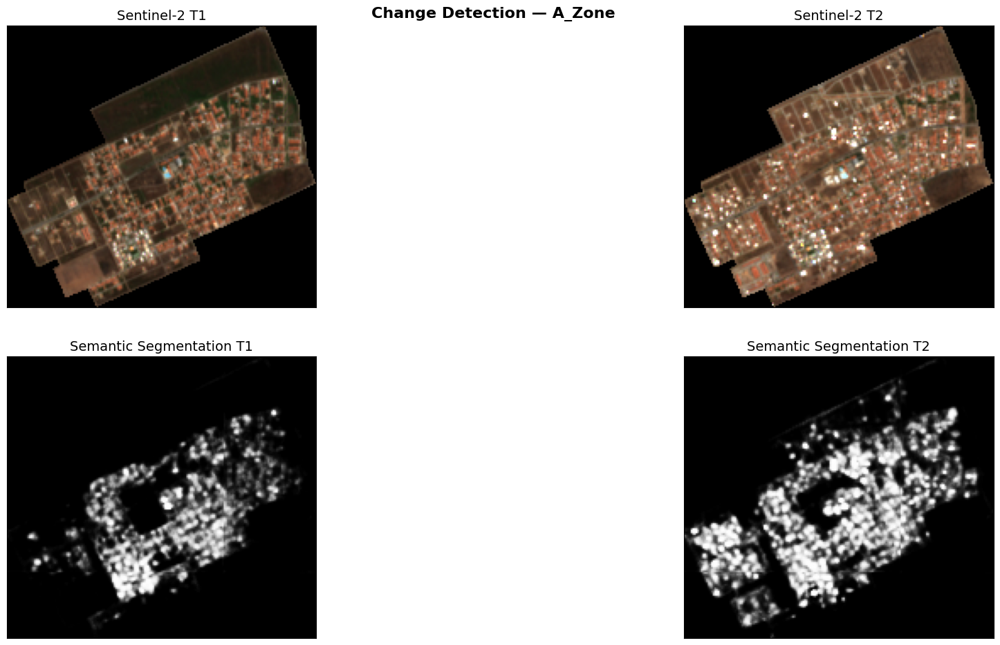

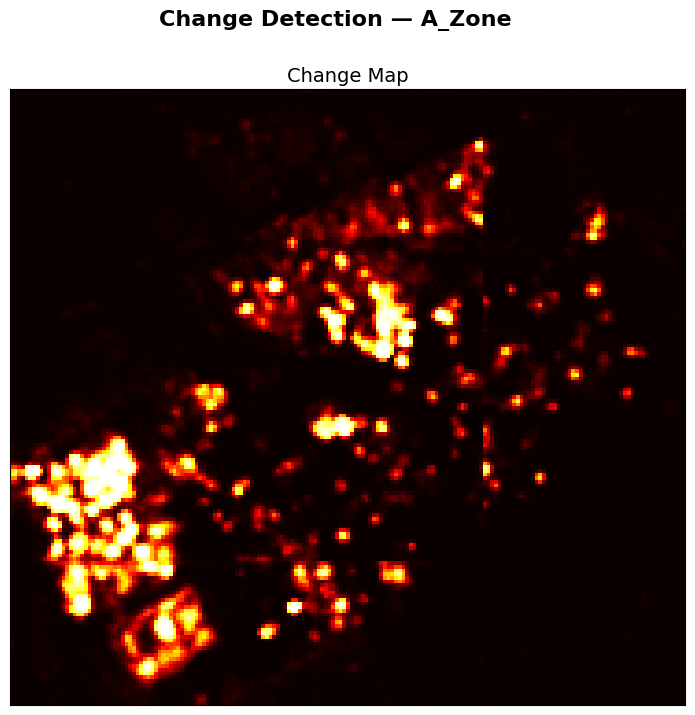


✅ Prediction saved at: /content/drive/MyDrive/Framework_Analise_Termica/Data/pred_A_Zone.tif


In [ ]:
# @title 6.2 — Run Change Detection Model {display-mode: "form"}
# @markdown ⏱️ Estimated time: ~2-5 min (depends on scene size)
import torch
print(f"🔧 GPU available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"🔧 GPU: {torch.cuda.get_device_name(0)}")

pred_file = run_inference(
    folder_imgs=folder_imgs,
    roi_name=cd_roi_name,
    folder_model=folder_model,
    model_name=model_name,
    tile_size=128
)

print(f"\n✅ Prediction saved at: {pred_file}")


**Before continuing:**
1. Wait for the cell above to finish
2. Confirm that the file `pred_<roi_name>.tif` appeared in the exported images folder (cell 6.1)
3. If a GPU error occurred, go to *Runtime → Change hardware type → GPU T4*

The AI model generates a **probability** map — each pixel has a value from 0 to 100 indicating how "likely" that point is to have undergone urban change.

Here we convert that map to a simple binary answer:
- **Value 1** → urban change detected (new building)
- **Value 0** → no significant change (no new building)

This map will be integrated with thermal analyses to answer the question:
> **What is the surface thermal behavior of the areas that grew the most?**

In [15]:
# @title 6.3 — Load the Probability Map {display-mode: "form"}
#@markdown
#@markdown Enter the full path of the file generated by the model in the previous step. The file has the prefix `pred_` followed by the ROI name (e.g., `pred_Renato_Parente_Loteamento.tif`).
#@markdown
#@markdown > 💡 You can copy the path by right-clicking the file in the Colab *Files* panel → *Copy path*.
#@markdown
#@markdown ---
pred_path = "/content/drive/MyDrive/Framework_Analise_Termica/Data/pred_A_Zone.tif"  # @param {type: "string"}
prediction_data, pred_transform, pred_crs, nodata, bounds, shape = load_geotiff(pred_path)

print(f"✅ Model result loaded successfully!")


✅ Model result loaded successfully!



✓ Threshold applied: 45.00
   • Change pixels (≥45.00): 1,721 (5.63%)
   • No-change pixels (<45.00): 28,840 (94.37%)


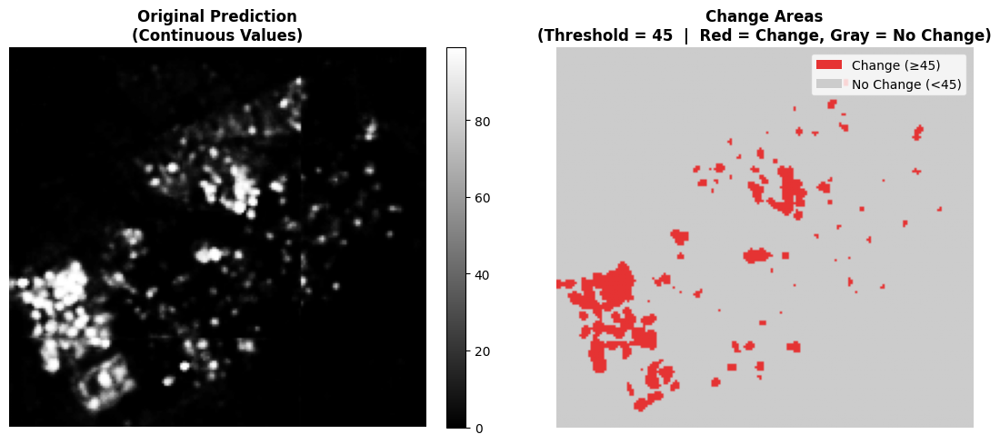


✅ Change map generated (threshold = 45)
   Area with detected change: 5.6% of the analyzed scene
   Pixels with change: 1,721 of 30,561 total

   Run 6.5 to integrate this map with Google Earth Engine.


In [16]:
# @title 6.4 — Convert Probability to Binary Change Map {display-mode: "form"}
# @markdown
# @markdown The U-Net model generated a **probability** map (0–100) for each pixel.
# @markdown Here we define the cutoff: pixels above the threshold → change detected.
# @markdown
# @markdown ---
# @markdown
# @markdown ## Threshold definition mode
modo_limiar = 'Manual'  # @param ['Automatic', 'Manual']
# @markdown > **Automatic** — uses the default threshold (45), validated in the Sobral study.
# @markdown
# @markdown > **Manual** — uses the value set on the slider below.
# @markdown >
# @markdown > Note: *Higher threshold → less area detected as change (more conservative)*.
# @markdown > *Lower threshold → more area detected as change (more sensitive)*
# @markdown
# @markdown ---
threshold_manual = 45  # @param {type: "slider", min: 0, max: 100, step: 5}

threshold = 45 if modo_limiar == 'Automatic' else threshold_manual

binary_mask = apply_threshold(prediction_data, threshold, nodata_value=nodata)
visualize_binary_mask(binary_mask, prediction_data, threshold)

# Summary statistics
_n_mudanca = int(binary_mask.sum())
_n_total   = int((binary_mask >= 0).sum())
_pct = 100 * _n_mudanca / _n_total if _n_total > 0 else 0

print(f"\n✅ Change map generated (threshold = {threshold})")
print(f"   Area with detected change: {_pct:.1f}% of the analyzed scene")
print(f"   Pixels with change: {_n_mudanca:,} of {_n_total:,} total")

if _pct > 40:
    print("\n💡 The change area seems high. Consider increasing the threshold in Manual mode.")
elif _pct < 2:
    print("\n💡 The change area seems low. Consider reducing the threshold in Manual mode.")
else:
    print("\n   Run 6.5 to integrate this map with Google Earth Engine.")


In [17]:
# @title 6.5 — Integrate Change Map into the Project {display-mode: "form"}
# @markdown Converts the binary map generated by the model to the format compatible
# @markdown with Google Earth Engine, enabling cross-referencing with thermal data.

from modulos.zonal_analysis import _numpy_mask_to_ee_image
try:
  _pt = globals().get('pred_transform')
  _pc = globals().get('pred_crs')

  if _pt is None or _pc is None:
    print("⚠️  pred_transform/pred_crs not found — mask will use ROI bounds for georeferencing.")
    print("   For precise alignment, run cell 6.3 (load the probability map) before this cell.")

  mask_ee = _numpy_mask_to_ee_image(
      binary_mask,
      roi,
      band_name="building_change",
      transform=_pt,
      crs=_pc,
  )
  print("✅ Change map integrated into the project!")
  print("   0 = no detected change  |  1 = new building")
except NameError as e:
  print(f"⚠️  Variable not found: {e}")
  print("   Make sure binary_mask and roi are defined (run the model inference cells first).")
except Exception as e:
  print(f"❌ Error: {e}")
  import traceback
  traceback.print_exc()


   → Vectorizing mask ((167, 183)) to polygons...
   ✓ 71 polygons vectorized
   ✓ Mask converted to ee.Image raster (band: 'building_change')
✅ Change map integrated into the project!
   0 = no detected change  |  1 = new building


In [ ]:
# @title 6.6 — Benchmark: U-Net vs Spectral Index Differencing (optional) {display-mode: "form"}
# @markdown Is the U-Net **more accurate** than the usual low-cost alternative, the difference of a spectral index
# @markdown between dates (e.g. ΔNDBI, the basis of the CDI of Silva and Torres, 2021)?
# @markdown Both are compared against the **same reference map** and computed from the **same Sentinel-2 images**.
# @markdown
# @markdown * **Otsu** — automatic threshold, no reference needed (how a municipality would use it);
# @markdown * **same area** — threshold that flags the same share of pixels as the U-Net (comparison at equal detected area);
# @markdown * **U-Net best** — threshold with the best F1 (optimistic: it uses the reference).
# @markdown
# @markdown F1, IoU, precision, recall and κ of the change class; 95% intervals by spatial block bootstrap.
# @markdown
# @markdown **Prerequisite:** cells 6.0–6.4 run for the area of the reference map (e.g. Zone B, 2016–2023),
# @markdown and a GeoTIFF reference map (any grid; it is resampled to the prediction grid).
# @markdown
# @markdown ---
reference_map_path = "/content/drive/MyDrive/Framework_Analise_Termica/Validation/ground_truth_B_Zone.tif"  # @param {type:"string"}
reference_change_value = 1  # @param {type:"integer"}
indices_benchmark = "NDBI, NBAI, DBSI, BSI, NDVI"  # @param {type:"string"}
n_boot_66 = 1000  # @param {type:"slider", min:200, max:2000, step:100}

from modulos.cd_benchmark import (benchmark_change_detection, print_change_benchmark,
                                  plot_change_benchmark)
import os
import matplotlib.pyplot as plt

if not os.path.isfile(reference_map_path):
    print(f'⚠️  Reference map not found: {reference_map_path}')
else:
    try:
        res_cd_benchmark = benchmark_change_detection(
            folder_imgs, cd_roi_name, reference_map_path,
            unet_threshold=float(globals().get('threshold', 45)),
            indices=tuple(x.strip().upper() for x in indices_benchmark.split(',') if x.strip()),
            change_values=(reference_change_value,),
            n_boot=n_boot_66,
        )
        print_change_benchmark(res_cd_benchmark)
        _fig = plot_change_benchmark(res_cd_benchmark)
        display(_fig)
        plt.close(_fig)
    except NameError as e:
        print(f'⚠️  Variable not found: {e} — run cells 6.1–6.4 first.')
    except (ValueError, FileNotFoundError) as e:
        print(f'⚠️  {e}')

## Section 7 — Spectral Index Mapping

**Spectral indices** translate satellite band combinations into interpretable information about the urban landscape — vegetation, imperviousness, moisture.

| Index | What it reveals | Relationship with heat |
|--------|-------------|----------------------|
| **NDVI** | Vegetation | ↑ NDVI → ↓ temperature |
| **NDBI** | Buildings, asphalt, bare soil | ↑ NDBI → ↑ temperature |
| **MNDWI** | Water and moisture | ↑ MNDWI → more water/moisture → ↓ temperature |

> **Optional** — This section is not required to proceed.
> Run it to visualize the available indices in the study area.


No single index works for all contexts [(Verstraete; Pinty, 1996)](https://doi.org/10.1109/36.536541). The choice must account for local characteristics (morphological and climatic). For example, indices such as NDVI and NDBI often fail in semi-arid regions ([Rasul *et al.*, 2018](https://doi.org/10.3390/land7030081); [Rouibah; Belabbas, 2020](https://doi.org/10.4995/raet.2020.13787)).

**Below is a list of common options:**

| Goal | Recommended index |
|---|---|
| Monitor urban vegetation | NDVI, SAVI (better for bare soil) |
| Detect built-up area expansion | NDBI |
| Identify water bodies | NDWI, MNDWI |
| Semi-arid (bare soil) | DBSI |

To give the user autonomy, the list below provides a catalog of hundreds of indices that can be tested, so the one that best fits the application context can be used.

> Note: Write down the exact index name (column `short_name`) — you will need it in the Section 8 analyses.

In [ ]:
# @title 7.1 — List of Available Spectral Indices {display-mode: "form"}
# @markdown Shows all indices compatible with both Landsat + Sentinel-2 from the [Awesome Spectral Indices](https://github.com/awesome-spectral-indices/awesome-spectral-indices/blob/main/output/spectral-indices-table.csv) catalog.
# @markdown Filter by application domain:
domain_filter = 'urban'  # @param ['None', 'vegetation', 'water', 'urban', 'soil', 'burn']

from modulos.spectral_analysis import list_available_indices

if domain_filter == 'None':
  domain_filter = None

df_indices = list_available_indices(
    platforms=['Sentinel-2', 'Landsat-OLI'],
    application_domain=domain_filter
)

display(df_indices[['short_name', 'long_name', 'domain', 'formula', 'reference']])
print(f'\nTotal available indices: {len(df_indices)}')
print('\nCopy the index names (short_name) you want to analyze to the following cells.')


AVAILABLE SPECTRAL INDEX CATALOG
  Total compatible indices (Landsat + Sentinel-2): 10
    • urban: 10 indices



,short_name,long_name,domain,formula,reference
0,BLFEI,Built-Up Land Features Extraction Index,urban,(((G+R+S2)/3.0)-S1)/(((G+R+S2)/3.0)+S1),https://doi.org/10.1080/10106049.2018.1497094
1,BRBA,Band Ratio for Built-up Area,urban,R/S1,https://www.omicsonline.org/scientific-reports...
2,IBI,Index-Based Built-Up Index,urban,(((S1-N)/(S1+N))-(((N-R)*(1.0+L)/(N+R+L))+((G-...,https://doi.org/10.1080/01431160802039957
3,NBAI,Normalized Built-up Area Index,urban,(S2-S1/G)/(S2+S1/G),https://www.omicsonline.org/scientific-reports...
4,NDBI,Normalized Difference Built-Up Index,urban,(S1-N)/(S1+N),http://dx.doi.org/10.1080/01431160304987
5,PISI,Perpendicular Impervious Surface Index,urban,0.8192*B-0.5735*N+0.0750,https://doi.org/10.3390/rs10101521
6,UI,Urban Index,urban,(S2-N)/(S2+N),https://www.isprs.org/proceedings/XXXI/congres...
7,VIBI,Vegetation Index Built-up Index,urban,((N-R)/(N+R))/(((N-R)/(N+R))+((S1-N)/(S1+N))),http://dx.doi.org/10.1080/01431161.2012.687842
8,VgNIRBI,Visible Green-Based Built-Up Index,urban,(G-N)/(G+N),https://doi.org/10.1016/j.ecolind.2015.03.037
9,VrNIRBI,Visible Red-Based Built-Up Index,urban,(R-N)/(R+N),https://doi.org/10.1016/j.ecolind.2015.03.037



Total available indices: 10

Copy the index names (short_name) you want to analyze to the following cells.


# 🔗 Outputs Data

**Here we analyze both the spectral-index-based change map and the U-Net network together with thermal maps (LST + UHI)** to understand the relationship between urban expansion and warming.

| Sections | Analysis | Question answered |
|:---|:---|:---|
| **8** Semantic (general) | Δ indices | • Which land-cover changes (vegetation loss, increase of impervious surfaces) have the greatest impact on surface warming between T1 and T2?<br>• What is the land cover profile (and how did it evolve) in the hottest zones versus the coolest zones? |
| **9** Binary (specific) | New buildings | • Did areas with new building expansions between T1 and T2 become significantly warmer than stable areas?  What was the magnitude of this effect?<br>• How did the spectral and thermal composition evolve by UHI intensity zone within new built-up areas? |

> The results of this section constitute the main evidence of the research on the surface thermal impact of urban expansion.

## Section 8 — Δ Indices


ℹ️  Sensor selected: Landsat-8 (30 m) — indices and correlations at 30 m.
   The interactive map displays Sentinel-2 indices (10 m).
Indices to analyze: ['SAVI', 'DBSI', 'NBAI']


── Analyzing: SAVI ──
   ℹ️  1774 valid pixels returned from 2000 requested (89%) — ROI ceiling reached.
      Increasing n_samples above 1774 will not change results.
   🔬 Outliers removed (3×IQR Δsavi): 3 points (0.2%)
      Δsavi range after filter: [-0.2601, 0.1969]


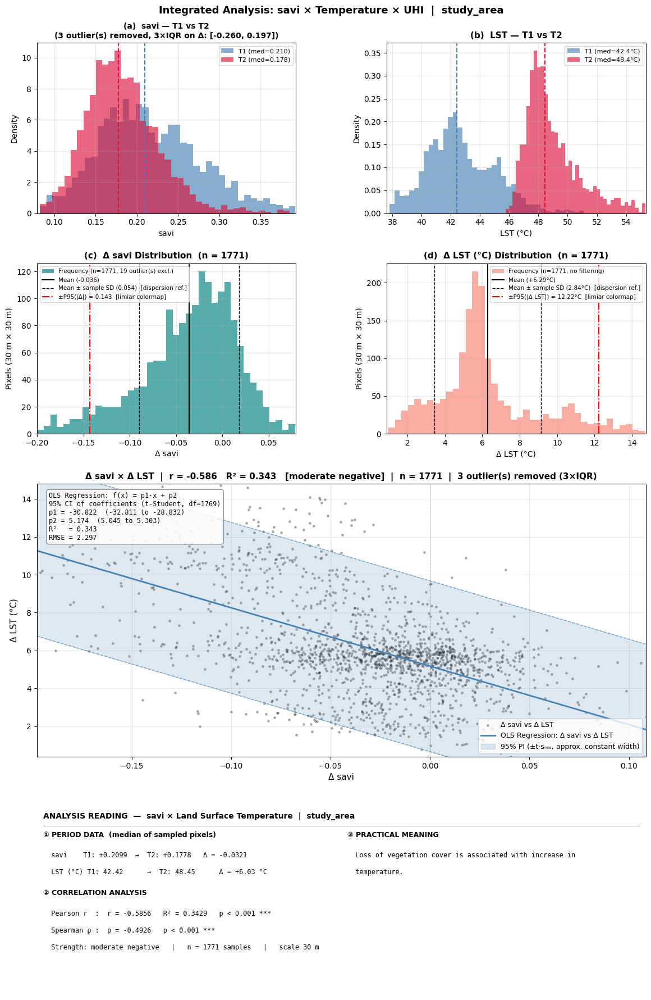


🗺️  Mapa — SAVI


Map(center=[-3.659560852057608, -40.3844099800147], controls=(WidgetControl(options=['position', 'transparent_…


── Analyzing: DBSI ──
   ℹ️  1774 valid pixels returned from 2000 requested (89%) — ROI ceiling reached.
      Increasing n_samples above 1774 will not change results.
   🔬 Outliers removed (3×IQR Δdbsi): 13 points (0.7%)
      Δdbsi range after filter: [-0.2361, 0.3018]


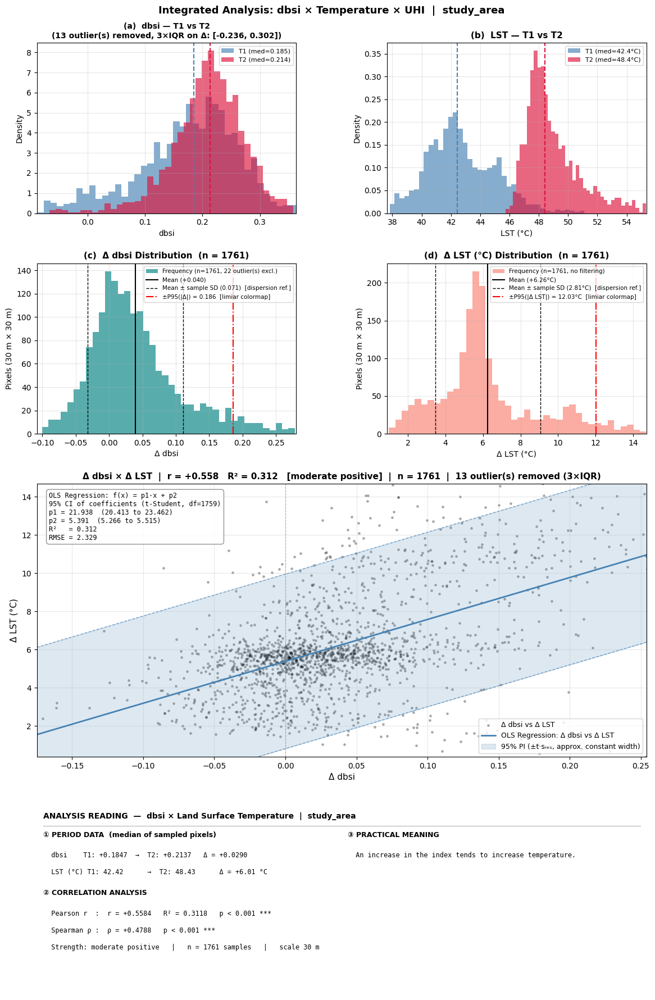


🗺️  Mapa — DBSI


Map(center=[-3.659560852057608, -40.3844099800147], controls=(WidgetControl(options=['position', 'transparent_…


── Analyzing: NBAI ──
   ℹ️  1774 valid pixels returned from 2000 requested (89%) — ROI ceiling reached.
      Increasing n_samples above 1774 will not change results.
   🔬 Outliers removed (3×IQR Δnbai): 5 points (0.3%)
      Δnbai range after filter: [-0.1582, 0.2399]


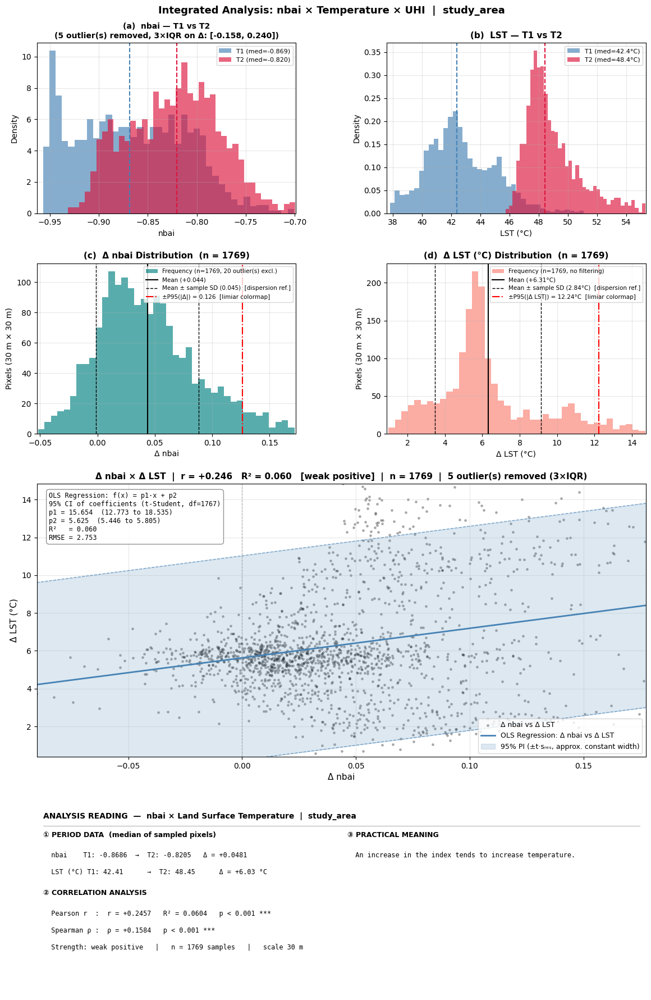


🗺️  Mapa — NBAI


Map(center=[-3.659560852057608, -40.3844099800147], controls=(WidgetControl(options=['position', 'transparent_…


✅ Analysis complete for 3 index/indices: ['SAVI', 'DBSI', 'NBAI']
   → Use one of these names in cell 9.1 (indice_referencia).


In [18]:
# @title 8.1 — Correlation between Vegetation/Imperviousness Change and Land Surface Temperature {display-mode: "form"}
# @markdown Analyzes the relationship between the **bitemporal variation** (T2 − T1) of each index
# @markdown and changes in land surface temperature (LST) and Surface Urban Heat Island (SUHI).
# @markdown
# @markdown **For each provided index, the cell produces:**
# @markdown - Overlapping T1 vs T2 distributions of the index and LST
# @markdown - Correlation scatter (Δ index × Δ LST) with regression line
# @markdown - Delta histograms (Δ index, Δ LST) and interpretation panel
# @markdown - Text summary with T1→T2 means and association tests
# @markdown - Interactive map with index, LST, delta, and Change Detection Index (CDI) layers
# @markdown
# @markdown ---
# @markdown ### Sensor for spectral indices
# @markdown Defines which sensor is used for the indices for **statistics and correlations**.
# @markdown - `Landsat 8` — recommended for most analyses (same resolution as the temperature map).
# @markdown - `Sentinel 2` — higher spatial detail in indices; however, correlation tends to reduce `r` values due to resolution differences.
# @markdown
# @markdown > Note: The **interactive map** always displays indices at high resolution (Sentinel-2) regardless of the choice above.
sensor_indices = "Landsat 8"  # @param ["Landsat 8", "Sentinel 2"]

# @markdown ---
# @markdown **`indices_para_analise`** — Indices to analyze (comma-separated).
# @markdown Provide any index from the **spyndex** catalog listed in cell 7.1 (e.g., `NDVI, NDBI, MNDWI`).

# ─── CONFIGURATION ─────────────────────────────────────────────────────────────────────────────
indices_para_analise = "SAVI, DBSI, NBAI"  # @param {type:"string"}

# @markdown ---
# @markdown ### Temperature (LST) scale of the map legend
lst_vis_min = 20  # @param {type:"number"}
lst_vis_max = 60  # @param {type:"number"}

# @markdown ---
# # @markdown ### Visualize CDI layer on interactive map
show_CDI = False

# # @markdown ---
# @markdown ### Sampling parameters (correlation)
# @markdown **Number of samples** — more samples = more precise statistics, but slower (recommended: 1000–2000):
n_amostras = 2000 # @param {type:"slider", min:100, max:2000, step:50}
# @markdown
# @markdown ---
# @markdown ### Sampling parameters (map view)
# @markdown **Threshold percentile (%)** — defines the cutoff for classifying changes as "strong" or "moderate" in interactive maps.
# @markdown A value of 90 means only the most extreme 10% are classified as "strong" — increase for more conservative maps:
percentil_limiar = 95 # @param {type:"slider", min:80, max:99, step:1}

# Default thermal palette (blue→green→yellow→red)
_LST_PALETTE = [
    '#313695','#4575b4','#74add1','#abd9e9',
    '#e0f3f8','#ffffbf','#fee090','#fdae61',
    '#f46d43','#d73027','#a50026'
]

# ─── RESOLVE INDEX LIST ─────────────────────────────────────────────────
_DEFAULT_INDICES = ['SAVI', 'DBSI', 'NBAI']

indices_analise = [idx.strip().upper() for idx in indices_para_analise.split(',') if idx.strip()]
if not indices_analise:
    indices_analise = _DEFAULT_INDICES
    print(f"⚠️  No index provided — using default: {indices_analise}")

# ─── RESOLVE DATA SOURCES ─────────────────────────────────────────────────────
lst_t1, lst_t1_label = results_bitemporal['lst_30m_t1'], 'Landsat 30m'
lst_t2, lst_t2_label = results_bitemporal['lst_30m_t2'], 'Landsat 30m'
uhi_t1 = stats_change['UHI_30m']['images']['t1']
uhi_t2 = stats_change['UHI_30m']['images']['t2']

# Indices for the MAP (always Sentinel-2, regardless of chosen sensor)
indices_map_t1 = dict(results_bitemporal['indices_sentinel2']['t1'])
indices_map_t2 = dict(results_bitemporal['indices_sentinel2']['t2'])
if 'indices_sentinel2_t1' in globals():
    indices_map_t1.update(dict(indices_sentinel2_t1))
    indices_map_t2.update(dict(indices_sentinel2_t2))

# Indices for STATISTICS: controlled by sensor_indices
if sensor_indices == "Landsat 8":
    _using_l8_indices = True
    print("ℹ️  Sensor selected: Landsat-8 (30 m) — indices and correlations at 30 m.")
    print("   The interactive map displays Sentinel-2 indices (10 m).")
elif sensor_indices == "Sentinel 2":
    _using_l8_indices = False
    print(f"ℹ️  Sensor selected: Sentinel-2 (10 m) — indices and correlations at 10 m.")

_scale_stats = 30 if _using_l8_indices else 10   # sampling scale for statistics/correlations

if _using_l8_indices:
    indices_stat_t1 = dict(results_bitemporal['indices_landsat']['t1'])
    indices_stat_t2 = dict(results_bitemporal['indices_landsat']['t2'])
else:
    indices_stat_t1 = dict(results_bitemporal['indices_sentinel2']['t1'])
    indices_stat_t2 = dict(results_bitemporal['indices_sentinel2']['t2'])
    if 'indices_sentinel2_t1' in globals():
        indices_stat_t1.update(dict(indices_sentinel2_t1))
        indices_stat_t2.update(dict(indices_sentinel2_t2))

# ─── COMPUTE MISSING INDICES DYNAMICALLY (spyndex / eemont) ─────────────────
from modulos.spectral_analysis import calculate_spectral_indices_dynamic
import matplotlib.pyplot as plt

_keys_stat_t1 = set(indices_stat_t1.keys())
_keys_stat_t2 = set(indices_stat_t2.keys())
_missing = [idx for idx in indices_analise
            if idx.lower() not in _keys_stat_t1 or idx.lower() not in _keys_stat_t2]

if _missing:
    print(f"\n⚙️  {len(_missing)} missing index/indices — computing via spyndex: {_missing}")
    if _using_l8_indices:
        _src_img_t1 = results_bitemporal['t1']['ls_optical']
        _src_img_t2 = results_bitemporal['t2']['ls_optical']
        _sensor_dyn = 'landsat'
    else:
        _src_img_t1 = globals().get('sentinel2_t1', results_bitemporal['s2_median_t1'])
        _src_img_t2 = globals().get('sentinel2_t2', results_bitemporal['s2_median_t2'])
        _sensor_dyn = 'sentinel2'
    _dyn_t1 = calculate_spectral_indices_dynamic(_src_img_t1, _missing, sensor=_sensor_dyn, verbose=False)
    _dyn_t2 = calculate_spectral_indices_dynamic(_src_img_t2, _missing, sensor=_sensor_dyn, verbose=False)
    indices_stat_t1.update(_dyn_t1)
    indices_stat_t2.update(_dyn_t2)
    _ok  = [k.upper() for k in _dyn_t1]
    _nok = [idx for idx in _missing if idx.lower() not in indices_stat_t1]
    if _ok:  print(f"   ✓ Computed ({_sensor_dyn}): {_ok}")
    if _nok: print(f"   ✗ Not found in spyndex catalog: {_nok}")
    if not _using_l8_indices:
        # stats used Sentinel-2 — sync spyndex-computed indices to map dicts as well
        indices_map_t1.update(_dyn_t1)
        indices_map_t2.update(_dyn_t2)

# Compute missing map indices via Sentinel-2 when stats use Landsat-8
if _using_l8_indices:
    _keys_map_t1 = set(indices_map_t1.keys())
    _keys_map_t2 = set(indices_map_t2.keys())
    _missing_map = [idx for idx in indices_analise
                    if idx.lower() not in _keys_map_t1 or idx.lower() not in _keys_map_t2]
    if _missing_map:
        _s2_src_t1 = globals().get('sentinel2_t1', results_bitemporal['s2_median_t1'])
        _s2_src_t2 = globals().get('sentinel2_t2', results_bitemporal['s2_median_t2'])
        _dyn_map_t1 = calculate_spectral_indices_dynamic(_s2_src_t1, _missing_map, sensor='sentinel2', verbose=False)
        _dyn_map_t2 = calculate_spectral_indices_dynamic(_s2_src_t2, _missing_map, sensor='sentinel2', verbose=False)
        indices_map_t1.update(_dyn_map_t1)
        indices_map_t2.update(_dyn_map_t2)
        _ok_map = [k.upper() for k in _dyn_map_t1]
        if _ok_map:
            print(f"   ✓ Map indices via spyndex (sentinel2): {_ok_map}")

print(f"Indices to analyze: {indices_analise}\n")

# ─── RUN ANALYSIS ────────────────────────────────────────────────────────────────────────
results_integration_all = {}
_lst_vis = {'min': lst_vis_min, 'max': lst_vis_max, 'palette': _LST_PALETTE}
_multi = len(indices_analise) > 1

for index_name in indices_analise:
    print(f'\n── Analyzing: {index_name.upper()} ──')

    try:
        results_integration = analyze_spectral_index_thermal_uhi_integration_gee(
            indices_t1_dict=indices_stat_t1,
            indices_t2_dict=indices_stat_t2,
            lst_t1_image=lst_t1,
            lst_t2_image=lst_t2,
            uhi_t1_image=uhi_t1,
            uhi_t2_image=uhi_t2,
            index_name=index_name.lower(),
            roi=roi,
            scale=_scale_stats,
            num_samples=n_amostras
        )
        results_integration_all[index_name.upper()] = results_integration

        # ── Quantitative information ──────────────────────────────────────────────────────
        fig_integration = create_correlation_plots(results_integration, percentile_threshold=percentil_limiar)
        display(fig_integration)
        plt.close(fig_integration)

        # ── Interactive map for this index ─────────────────────────────────────────────
        if _multi:
            print(f"\n🗺️  Mapa — {index_name.upper()}")
        # Map always uses Sentinel-2 indices (indices_map_t1/t2), regardless of sensor_indices
        _s2_t1_img = indices_map_t1.get(index_name.lower())
        _s2_t2_img = indices_map_t2.get(index_name.lower())
        if _s2_t1_img is not None and _s2_t2_img is not None:
            _res_for_map = dict(results_integration)
            _imgs_for_map = dict(results_integration.get('images', {}))
            _imgs_for_map['index_t1'] = _s2_t1_img
            _imgs_for_map['index_t2'] = _s2_t2_img
            _imgs_for_map['delta_index'] = _s2_t2_img.subtract(_s2_t1_img).rename('delta_index')
            _res_for_map['images'] = _imgs_for_map
        else:
            _res_for_map = results_integration
        map_idx = create_interactive_analysis_map(
            results_bitemporal, roi,
            _res_for_map, zoom=zoom_map,
            lst_t1=lst_t1, lst_t2=lst_t2, lst_vis=_lst_vis,
            lst_t1_label=lst_t1_label, lst_t2_label=lst_t2_label,
            percentile_threshold=percentil_limiar,
            show_CDI=show_CDI)
        display(map_idx)

    except Exception as e:
        print(f'Error analyzing {index_name}: {e}')

print(f'\n✅ Analysis complete for {len(results_integration_all)} index/indices: {list(results_integration_all.keys())}')
print('   → Use one of these names in cell 9.1 (indice_referencia).')


**Legend of abbreviations — Interactive maps from correlation analysis (8.1)**

Abbreviations in the correlation maps represent variation categories computed automatically by the percentile defined above.
| Abbrev. | Δ Vegetation index | Δ Other indices |
|---|---|---|
| **SL / SD** | Strong Vegetation Loss | Strong Decrease |
| **ML / MD** | Moderate Loss | Moderate Decrease |
| **Stb** | Stable | Stable |
| **MG / MI** | Moderate Gain | Moderate Increase |
| **SG / SI** | Strong Vegetation Gain | Strong Increase |

> **Δ LST (Temperature):** SC = Strong Cooling · MC = Moderate Cooling · Stb = Stable · MW = Moderate Warming · SW = Strong Warming

JOINT EXPLANATORY POWER — ΔSAVI + ΔDBSI + ΔNBAI → Δ UHI (z)
n = 1755 samples at 30 m | 26 spatial blocks of 300 m for the 95% CI

                                R²   95% CI (block bootstrap)
Individual ΔSAVI             0.337   [0.144, 0.464]
Individual ΔDBSI             0.308   [0.066, 0.494]
Individual ΔNBAI             0.053   [0.000, 0.205]
Sum of individual R²         0.698   (double-counts the shared part)
Joint model                  0.399   [0.258, 0.538]
Joint model (adjusted)       0.398

Partition of the joint R²:
   unique to ΔSAVI           0.082   [0.002, 0.294]
   unique to ΔDBSI           0.026   [0.000, 0.116]
   unique to ΔNBAI           0.015   [0.000, 0.145]
   shared                0.276   [-0.042, 0.422]

Collinearity:
   VIF ΔSAVI         3.46    standardized β = -0.532
   VIF ΔDBSI         2.15    standardized β = +0.234
   VIF ΔNBAI         1.96    standardized β = -0.174
   (VIF > 5 indicates strong overlap between predictors)

Correlation with ΔUHI (z):     

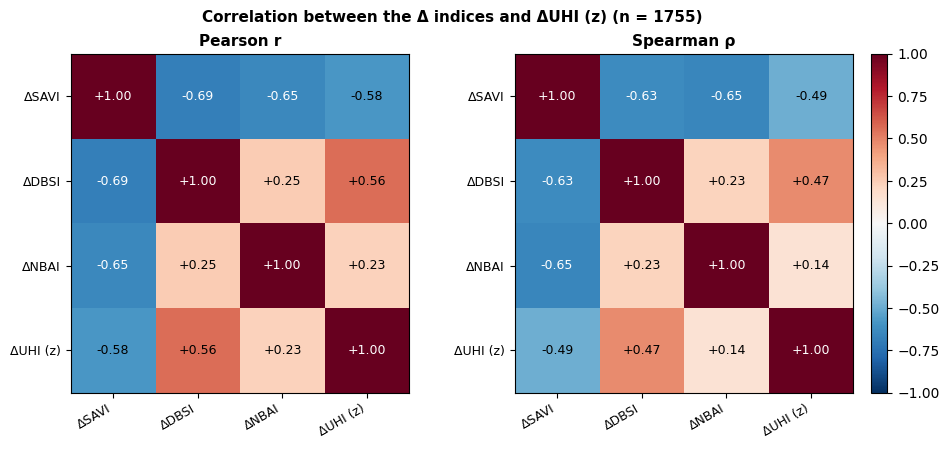

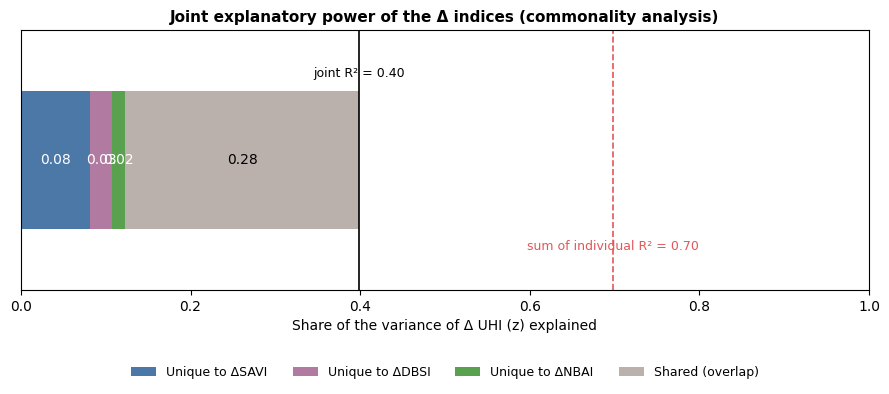

In [19]:
# @title 8.1b — Joint Contribution of the Indices (collinearity) {display-mode: "form"}
# @markdown Correlated indices explain overlapping parts of the thermal change: SAVI and DBSI, for example, both contain the NDVI term.
# @markdown Their individual R² (cell 8.1) therefore **cannot be summed**.
# @markdown
# @markdown This cell reports, for the indices analyzed in 8.1 and the same sensor and scale:
# @markdown * (1) correlation matrix between the Δ indices and the thermal change (Pearson and Spearman);
# @markdown * (2) partial correlation of each index, holding the others constant, and VIF;
# @markdown * (3) the joint R² split into the part **unique** to each index and the part they **share** (commonality analysis),
# @markdown with 95% intervals from a spatial block bootstrap (blocks of 300 m).
# @markdown
# @markdown **Prerequisite:** cell 8.1 with at least two indices.
# @markdown
# @markdown ---
resposta_81b = 'Δ UHI (z, relative to the city)'  # @param ['Δ UHI (z, relative to the city)', 'Δ LST (°C)']
n_boot_81b = 500  # @param {type:"slider", min:100, max:2000, step:100}

from modulos.stats_analysis import (analyze_joint_index_regression, print_joint_regression_summary,
                                    plot_joint_regression, plot_correlation_matrix)
import matplotlib.pyplot as plt

try:
    _idx_81b = [i for i in indices_analise if i.lower() in indices_stat_t1 and i.lower() in indices_stat_t2]
    if len(_idx_81b) < 2:
        print('⚠️  Analyze at least two indices in cell 8.1 first.')
    else:
        res_joint = analyze_joint_index_regression(
            indices_stat_t1, indices_stat_t2, _idx_81b,
            lst_t1, lst_t2, roi,
            uhi_t1_image=stats_change['UHI_30m']['images']['t1'],
            uhi_t2_image=stats_change['UHI_30m']['images']['t2'],
            response='delta_uhi' if resposta_81b.startswith('Δ UHI') else 'delta_lst',
            scale=_scale_stats, num_samples=n_amostras,
            block_size_m=300, n_boot=n_boot_81b,
        )
        print_joint_regression_summary(res_joint)
        for _fig in (plot_correlation_matrix(res_joint), plot_joint_regression(res_joint)):
            display(_fig)
            plt.close(_fig)
except NameError as e:
    print(f'⚠️  Variable not found: {e} — run cells 5.1 and 8.1 first.')


ℹ️  Sampling T1 and T2 to compute standardized scale (T1 ∪ T2)...

── Sampling T1 ────────────────────────────────────────────────────────────────────────

ZONAL ANALYSIS BY UHI CLASSES (Deng et al., 2023)
   Bands for sampling: uhi_zone, LST, SAVI, DBSI, NBAI
   Requested samples: 2000
   Sampling via stratifiedSample...
   ✓ 1614 samples retrieved

────────────────────────────────────────────────────────────────────────────────
Zone                    LST        SAVI        DBSI        NBAI       N
────────────────────────────────────────────────────────────────────────────────
LTZ (Low)           39.8947      0.2426      0.1287     -0.8952     400
SLTZ (Sub-Low)      41.5238      0.1741      0.2246     -0.8122     317
MTZ (Medium)        42.8305      0.1686      0.2320     -0.8304     400
SHTZ (Sub-High)     44.5404      0.1597      0.2705     -0.8587     177
HTZ (High)          46.3925      0.1322      0.2818     -0.8618     320
─────────────────────────────────────────────────────

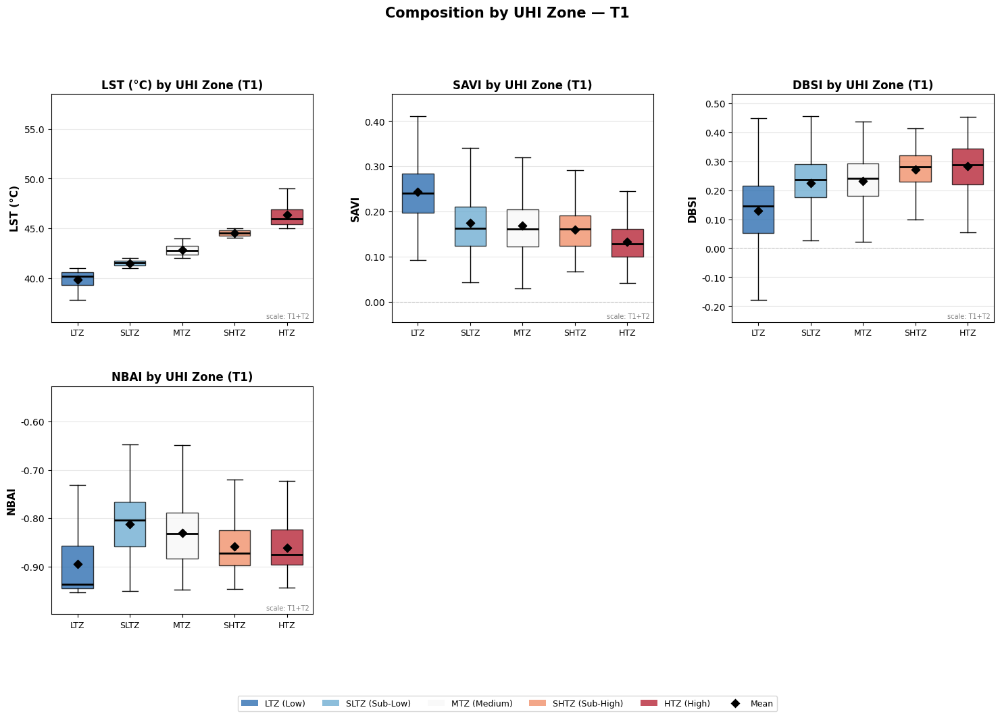

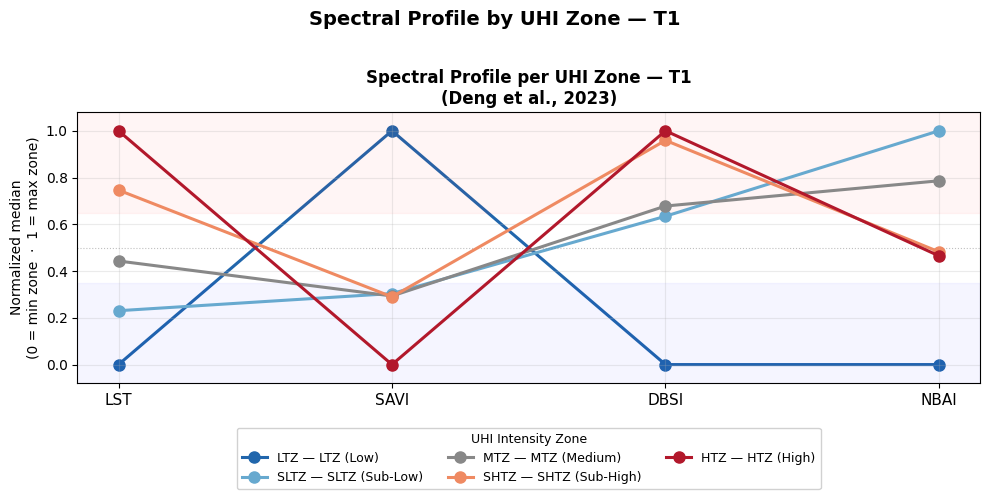

Map(center=[-3.6595608533858632, -40.384409980402324], controls=(WidgetControl(options=['position', 'transpare…

In [20]:
# @title 8.2 — Characterization by UHI Intensity Classes {display-mode: "form"}
# @markdown Analyzes the morphological composition (spectral indices) and thermal (LST)
# @markdown in each UHI intensity zone (Deng et al., 2023).
# @markdown
# @markdown > Uses **Sentinel-2 (10 m)** indices and original **Landsat LST (30 m)**.
# @markdown
# @markdown > If `delta`, analyzes the **variation** between T1 and T2 (what changed). If `T1` or `T2`, analyzes the absolute value of a single period.
# @markdown
# @markdown > **Scale standardization**: for `T1` and `T2`, both periods are always
# @markdown sampled so that boxplot Y-axes use the global min/max of T1 ∪ T2.
# @markdown This enables direct visual comparison across separate execution sessions.
# @markdown For `delta`, a symmetric scale around 0 is applied automatically.
# @markdown ---
# @markdown **This cell generates:**
# @markdown
# @markdown * (1) Boxplots showing the temperature and index distribution in each heat zone;
# @markdown * (2) Spectral profile by UHI zone (normalized median per zone);
# @markdown * (3) Interactive map with UHI intensity zones overlaid on the satellite image.
# @markdown ---
# @markdown Configuration
# @markdown
# @markdown **Period to analyze:**

periodo_uhi         = "T1"          # @param ["T1", "T2", "delta"]
indices_uhi_analise = "SAVI, DBSI, NBAI" # @param {type: "string"}
n_samples_uhi       = 2000

from modulos.zonal_analysis import (analyze_uhi_zones, plot_uhi_zones_boxplots,
                                     plot_uhi_spectral_profile, compute_global_band_limits,
                                     create_uhi_zones_map)
from modulos.spectral_analysis import calculate_spectral_indices_dynamic
import matplotlib.pyplot as plt

try:
    indices_list = [x.strip().upper() for x in indices_uhi_analise.split(",") if x.strip()]

    # ─── DATA SOURCES ───────────────────────────────────────────────────────
    s2_t1 = results_bitemporal["t1"]["sentinel2_image"]
    s2_t2 = results_bitemporal["t2"]["sentinel2_image"]

    uhi_t1 = stats_change["UHI_30m"]["images"]["t1"]
    uhi_t2 = stats_change["UHI_30m"]["images"]["t2"]

    lst_t1, lst_t1_label = results_bitemporal["lst_30m_t1"], "Landsat 30m"
    lst_t2, lst_t2_label = results_bitemporal["lst_30m_t2"], "Landsat 30m"

    # ─── RESOLVE INDICES HELPER ────────────────────────────────────────────────
    try:
        _resolve_s2
    except NameError:
        def _resolve_s2(nome, periodo):
            if "indices_sentinel2_t1" in globals():
                src = indices_sentinel2_t1 if periodo == "T1" else indices_sentinel2_t2
            else:
                src = (results_bitemporal["indices_sentinel2"]["t1"] if periodo == "T1"
                       else results_bitemporal["indices_sentinel2"]["t2"])
            if nome.lower() in src:
                return src[nome.lower()]
            img = s2_t1 if periodo == "T1" else s2_t2
            result = calculate_spectral_indices_dynamic(img, [nome], sensor="sentinel2", verbose=False)
            return result.get(nome.lower()) or result.get(nome.upper())

    # ─── BUILD INDEX DICTS AND RUN ZONAL ANALYSIS ───────────────────────
    if periodo_uhi == "delta":
        # Delta: single computation, symmetric scale applied automatically
        indices_dict = {}
        for idx_name in indices_list:
            img_t1 = _resolve_s2(idx_name, "T1")
            img_t2 = _resolve_s2(idx_name, "T2")
            if img_t1 is not None and img_t2 is not None:
                indices_dict[idx_name] = img_t2.subtract(img_t1)
            else:
                print(f"   ❌ Unable to calculate {idx_name}")

        uhi_img      = uhi_t2.subtract(uhi_t1)
        lst_img      = lst_t2.subtract(lst_t1)
        sentinel_img = results_bitemporal["s2_median_t2"]

        if not indices_dict:
            print("\n❌ No index could be calculated!")
            raise SystemExit()

        result_zones       = analyze_uhi_zones(uhi_img, lst_img, indices_dict,
                                               roi=roi, scale=30, n_samples=n_samples_uhi)
        band_limits_global = None  # symmetric ±max_abs handled inside plot function

    else:
        # T1 or T2: always sample BOTH periods to build standardized Y-axis limits
        print("ℹ️  Sampling T1 and T2 to compute standardized scale (T1 ∪ T2)...")

        indices_t1, indices_t2 = {}, {}
        for idx_name in indices_list:
            img1 = _resolve_s2(idx_name, "T1")
            img2 = _resolve_s2(idx_name, "T2")
            if img1 is not None:
                indices_t1[idx_name] = img1
            if img2 is not None:
                indices_t2[idx_name] = img2
            if img1 is None or img2 is None:
                print(f"   ❌ Unable to resolve {idx_name}")

        if not indices_t1 and not indices_t2:
            print("\n❌ No index could be calculated!")
            raise SystemExit()

        print("\n── Sampling T1 ────────────────────────────────────────────────────────────────────────")
        result_zones_t1 = analyze_uhi_zones(uhi_t1, lst_t1, indices_t1,
                                             roi=roi, scale=30, n_samples=n_samples_uhi)

        print("\n── Sampling T2 ────────────────────────────────────────────────────────────────────────")
        result_zones_t2 = analyze_uhi_zones(uhi_t2, lst_t2, indices_t2,
                                             roi=roi, scale=30, n_samples=n_samples_uhi)

        if result_zones_t1 is not None and result_zones_t2 is not None:
            band_limits_global = compute_global_band_limits(result_zones_t1, result_zones_t2)
            print(f"\n✅ Global limits computed for: {list(band_limits_global.keys())}")
        else:
            band_limits_global = None
            print("\n⚠️  Could not compute global limits — using auto-scale.")

        if periodo_uhi == "T1":
            result_zones = result_zones_t1
            indices_dict = indices_t1
            sentinel_img = results_bitemporal["s2_median_t1"]
            uhi_img      = uhi_t1
        else:
            result_zones = result_zones_t2
            indices_dict = indices_t2
            sentinel_img = results_bitemporal["s2_median_t2"]
            uhi_img      = uhi_t2

    # ─── PLOTS ────────────────────────────────────────────────────────────────────────────
    if result_zones is not None:
        fig_bp = plot_uhi_zones_boxplots(result_zones, periodo=periodo_uhi,
                                         band_limits=band_limits_global)
        display(fig_bp)
        plt.close(fig_bp)
        print(" ")

        fig_prof = plot_uhi_spectral_profile(result_zones, periodo=periodo_uhi)
        if fig_prof is not None:
            display(fig_prof)
            plt.close(fig_prof)
            print(" ")

        Map_uhi_zones = create_uhi_zones_map(
            uhi_classified=result_zones["uhi_classified"],
            roi=roi,
            sentinel_image=sentinel_img,
            zoom=zoom_map,
            periodo=periodo_uhi,
            sentinel_image_t1=s2_t1 if periodo_uhi == "delta" else None,
            indices_dict=indices_dict
        )
        display(Map_uhi_zones)

except NameError as e:
    print(f"⚠️  Variable not found: {e} — first run cells 5.1 and 8.1.")
except Exception as e:
    print(f"❌ Error: {e}")
    import traceback; traceback.print_exc()


---
## Section 9 — New Buildings


📊 Test of the Research Central Hypothesis

> **Question**: Did areas with new buildings (detected by the AI model) become significantly warmer between T1 and T2?

The analysis below compares the **temperature variation** (ΔT = T2 − T1) between two groups:
- **Group "With new buildings"** — pixels where the U-Net model detected a new building
- **Group "Without new buildings"** — pixels without significant change in the period

If the difference between groups is statistically significant, we have evidence that **urban expansion (new buildings) contributed to local warming** in the study area.

✅ Using results from: SAVI
ℹ️  Sensor selected: Landsat-8 — zonal analysis at 30 m scale.
   🔬 Outliers removed 3×IQR Δsavi [no_change]: 3 (0.2%)

✅ ZONAL ANALYSIS COMPLETE


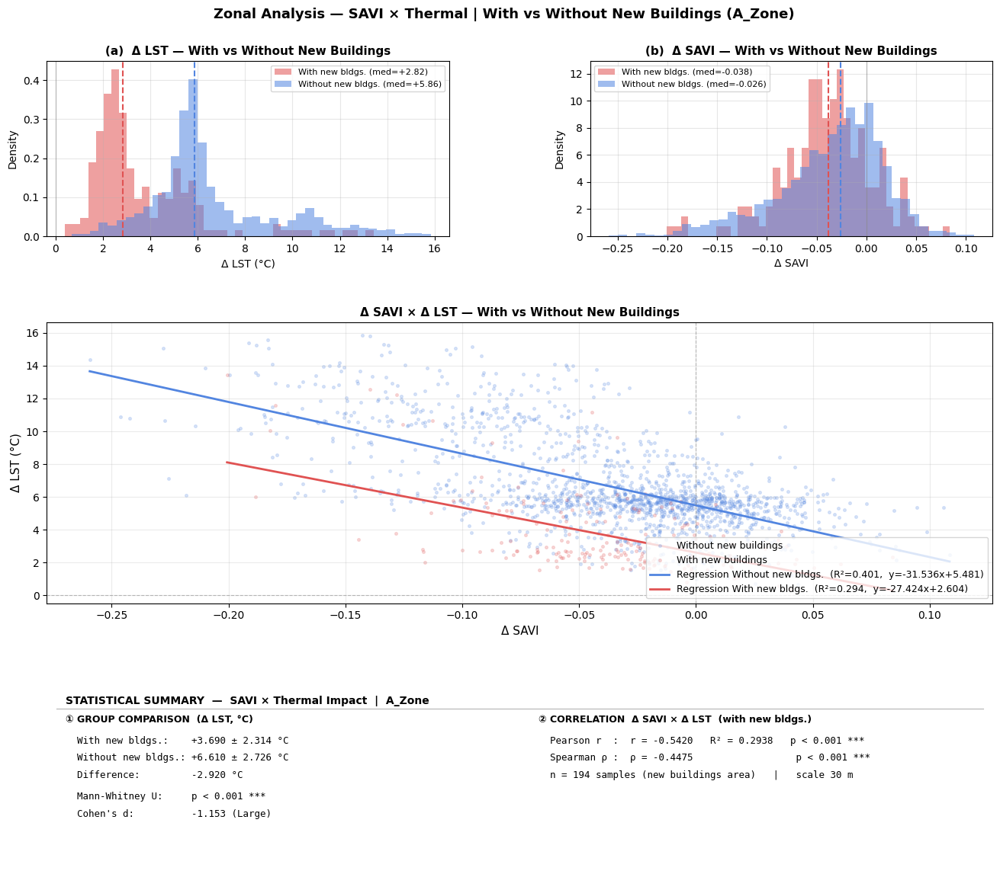

Map(center=[-3.659560853386012, -40.38440998039631], controls=(WidgetControl(options=['position', 'transparent…

In [21]:
# @title 9.1 — Compare Zones with and without New Buildings {display-mode: "form"}
# @markdown Compares thermal metrics (LST, UHI) between areas where the U-Net model detected
# @markdown new buildings and areas without new buildings — **direct test of the project's central hypothesis**.
# @markdown
# @markdown **Prerequisite:** run 6.5 and 8.1 at least once.
# ─── CONFIGURATION ─────────────────────────────────────────────────────────────────────────────
# @markdown **Reference index** — must be **ONE** of the indices analyzed in 8.1.
indice_referencia = "SAVI"  # @param {type:"string"}

# @markdown ---
# @markdown ### Sensor for zonal analysis
# @markdown Defines the spatial scale used in the statistical analysis of zones.
# @markdown - `auto` — segue o sensor escolhido em 8.1 (recomendado).
# @markdown - `Landsat 8` — forces 30 m scale.
# @markdown - `Sentinel 2` — forces 10 m scale.
sensor_indices_92 = "Landsat 8"  # @param ["auto", "Landsat 8", "Sentinel 2"]

# @markdown ---
# @markdown **Number of samples per group** (with new buildings / without new buildings):
amostras       = 2000  # @param {type:"integer"}

# # @markdown ---
# # @markdown ### Visualize CDI layer on interactive map
show_CDI = False

# ─── VALIDATE DEPENDENCIES ───────────────────────────────────────────────────
try:
  results_integration_all
except NameError:
  print("⚠️  Run cell 8.1 first to generate the integration data.")
  raise SystemExit()

chave = indice_referencia.strip().upper()
if chave not in results_integration_all:
  disponiveis = list(results_integration_all.keys())
  print(f"⚠️  Index '{chave}' not found in results_integration_all.")
  print(f"   Available: {disponiveis}")
  print(f"   Using the last analyzed: '{disponiveis[-1]}'")
  chave = disponiveis[-1]

results_integration = results_integration_all[chave]
print(f"✅ Using results from: {chave}")

# ─── ZONAL ANALYSIS ──────────────────────────────────────────────────────────
if sensor_indices_92 == "Landsat 8":
  _scale_zonal = 30
  print("ℹ️  Sensor selected: Landsat-8 — zonal analysis at 30 m scale.")
elif sensor_indices_92 == "Sentinel 2":
  _scale_zonal = 10
  print("ℹ️  Sensor selected: Sentinel-2 — zonal analysis at 10 m scale.")
else:  # "auto": follows the sensor chosen in 8.1
  _scale_zonal = 30 if globals().get('_using_l8_indices', True) else 10
  print(f"ℹ️  [auto] Following cell 8.1 — zonal analysis at {_scale_zonal} m scale.")

zonal_results = apply_building_change_mask_to_results(
    results_dict=results_integration,
    binary_change_mask=binary_mask,
    roi=roi,
    scale=_scale_zonal,
    output_dir=None,
    roi_name=roi_name,
    mask_name='Mudanca_Urbana',
    mask_ee=mask_ee,
    verbose=False,
    show_violin=False,
    num_points=amostras,   # samples per group (with / without new buildings)
)
# ─── HTML SUMMARY TABLE ───────────────────────────────────────────────────────
if zonal_results and 'differences' in zonal_results:
  from IPython.display import display, HTML
  import numpy as np

  dif   = zonal_results['differences']
  sc    = zonal_results['stats_change']
  snc   = zonal_results['stats_no_change']
  stat  = zonal_results.get('statistics', {})
  interp = zonal_results.get('interpretation', '')

  n_chg = zonal_results.get('n_change_pixels', sc['delta_lst']['count'])
  n_tot = zonal_results.get('n_total_pixels', None)
  pct   = f"{n_chg / n_tot * 100:.1f}%" if n_tot else "—"

  # helpers ─────────────────────────────────────────────────────────────────
  def _stars(p):
    if p is None or (isinstance(p, float) and np.isnan(p)):
      return ''
    if p < 0.001: return ' <b>***</b>'
    if p < 0.01:  return ' <b>**</b>'
    if p < 0.05:  return ' <b>*</b>'
    return ' ns'

  def _d_label(d):
    if d is None or (isinstance(d, float) and np.isnan(d)):
      return '—'
    ad = abs(d)
    if ad < 0.2:   label = 'negligible'
    elif ad < 0.5: label = 'small'
    elif ad < 0.8: label = 'medium'
    else:           label = 'large'
    return f"{d:+.3f} ({label})"

  # Colors for Δ difference: saturated enough for contrast on
  # light AND dark backgrounds (avoid very dark red/blue)

  def _color_dif(v):
    return '#e05a5a' if v > 0 else '#5a8fd4'

  def _fmt_pv(p):
    # p-value is None when one of the groups has too few samples for the test
    return '—' if p is None or (isinstance(p, float) and np.isnan(p)) else f"p={p:.4f}"

  p_lst = stat.get('p_mannwhitney_lst')
  p_uhi = stat.get('p_mannwhitney_uhi')
  d_lst = stat.get('cohens_d_lst')
  d_uhi = stat.get('cohens_d_uhi')
  dif_lst_val = dif['delta_lst']
  dif_uhi_val = dif['delta_uhi']

  # ─── Correlation extraction (Pearson + Spearman — new buildings) ────────────
  _corr = zonal_results.get('correlations', {}).get('index_lst', {})
  _pr   = _corr.get('pearson_r',    float('nan'))
  _pp   = _corr.get('pearson_p',    float('nan'))
  _r2   = _corr.get('r2',           float('nan'))
  _sr   = _corr.get('spearman_rho', float('nan'))
  _sp   = _corr.get('spearman_p',   float('nan'))

  # CSS: theme variables + dark-mode via media query and .zon-dark class
  # The .zon-dark class is added by JS if the notebook is in dark mode.
  _css = """
<style>
  /* ── Light theme (default) ────────────────────────────────────── */
  .zon-wrap {
    --zon-th-bg:       #2c3e50;
    --zon-th-fg:       #ffffff;
    --zon-row-odd:     #f2f5f7;
    --zon-row-even:    #ffffff;
    --zon-border:      rgba(0,0,0,0.12);
    --zon-text:        #1a1a1a;
    --zon-meta:        #555555;
    --zon-box-bg:      rgba(255, 248, 180, 0.7);
    --zon-box-border:  rgba(0,0,0,0.12);
    --zon-leg-fg:      #555555;
    --zon-leg-accent:  #e67e22;
    font-family: monospace;
    font-size: 13px;
    color: var(--zon-text);
  }

  /* ── Dark theme: media query (system-level dark mode) ─────── */
  @media (prefers-color-scheme: dark) {
    .zon-wrap {
      --zon-th-bg:       #1a3a5c;
      --zon-th-fg:       #e8e8e8;
      --zon-row-odd:     rgba(255,255,255,0.07);
      --zon-row-even:    rgba(255,255,255,0.02);
      --zon-border:      rgba(255,255,255,0.14);
      --zon-text:        #dcdcdc;
      --zon-meta:        #aaaaaa;
      --zon-box-bg:      rgba(255, 220, 60, 0.10);
      --zon-box-border:  rgba(255,255,255,0.14);
      --zon-leg-fg:      #999999;
      --zon-leg-accent:  #f39c12;
    }
  }

  /* ── Dark theme: class injected by JS (Colab / JupyterLab) ─ */
  .zon-wrap.zon-dark {
    --zon-th-bg:       #1a3a5c;
    --zon-th-fg:       #e8e8e8;
    --zon-row-odd:     rgba(255,255,255,0.07);
    --zon-row-even:    rgba(255,255,255,0.02);
    --zon-border:      rgba(255,255,255,0.14);
    --zon-text:        #dcdcdc;
    --zon-meta:        #aaaaaa;
    --zon-box-bg:      rgba(255, 220, 60, 0.10);
    --zon-box-border:  rgba(255,255,255,0.14);
    --zon-leg-fg:      #999999;
    --zon-leg-accent:  #f39c12;
  }

  /* ── Components ────────────────────────────────────────────── */
  .zon-table {
    border-collapse: collapse;
    width: 100%;
  }
  .zon-table th {
    background: var(--zon-th-bg);
    color: var(--zon-th-fg);
    padding: 7px 12px;
    text-align: center;
  }
  .zon-table td {
    padding: 6px 12px;
    border-bottom: 1px solid var(--zon-border);
    text-align: center;
    color: var(--zon-text);
  }
  .zon-table tr:nth-child(odd)  td { background: var(--zon-row-odd); }
  .zon-table tr:nth-child(even) td { background: var(--zon-row-even); }

  .zon-box {
    border: 1px solid var(--zon-box-border);
    border-left: 4px solid var(--zon-leg-accent);
    border-radius: 6px;
    padding: 12px 16px;
    background: var(--zon-box-bg);
    font-size: 13px;
    line-height: 1.6;
    margin-top: 10px;
    color: var(--zon-text);
  }
  .zon-leg {
    padding-left: 10px;
    margin-top: 8px;
    font-size: 12px;
    color: var(--zon-leg-fg);
    border-left: 3px solid var(--zon-leg-accent);
  }
  .zon-meta { color: var(--zon-meta); font-size: 12px; margin: 0 0 8px; }
</style>
"""
  # JS: detects dark mode by luminance of body/cell background and adds .zon-dark
  _js = """
<script>
(function(){
  var wraps = document.querySelectorAll('.zon-wrap');
  if (!wraps.length) return;
  function isDark(el) {
    while (el && el !== document.body) {
      var bg = window.getComputedStyle(el).backgroundColor;
      var m = bg.match(/rgba?\\((\\d+),\\s*(\\d+),\\s*(\\d+)/);
      if (m) {
        var lum = (0.299*+m[1] + 0.587*+m[2] + 0.114*+m[3]) / 255;
        if (lum < 0.45) return true;
        if (lum > 0.55) return false;
      }
      el = el.parentElement;
    }
    // fallback: check body
    var bg = window.getComputedStyle(document.body).backgroundColor;
    var m = bg.match(/rgba?\\((\\d+),\\s*(\\d+),\\s*(\\d+)/);
    if (m) {
      var lum = (0.299*+m[1] + 0.587*+m[2] + 0.114*+m[3]) / 255;
      return lum < 0.45;
    }
    return false;
  }
   wraps.forEach(function(w){
     if (isDark(w)) w.classList.add('zon-dark');
  });
})();
</script>
"""

  _header = (
      "<h4 style='margin-bottom:4px'>📊 Thermal Impact — Areas with New Buildings vs Without New Buildings</h4>"
      f"<p class='zon-meta'>"
      f"Area: <b>{roi_name}</b> &nbsp;|&nbsp; Index: <b>{chave}</b> &nbsp;|&nbsp;"
      f"Detected pixels: <b>{n_chg:,}</b> ({pct} of area) &nbsp;|&nbsp;"
      f"Samples by group: <b>{sc['delta_lst']['count']:,}</b>"
      "</p>"
  )

  _thead = (
      "<table class='zon-table'><tr>"
      "<th>Metric</th>"
      "<th>🔴 With new buildings</th>"
      "<th>🔵 Without new buildings<br><small>(control area)</small></th>"
      "<th>Δ Difference</th>"
      "<th>Significance<br><small>(Mann-Whitney U)</small></th>"
      "<th>Effect Size<br><small>(Cohen's d)</small></th>"        "</tr>"
  )
  _row_lst = (
      "<tr>"
      "<td><b>Δ LST (°C)</b><br><small>T2−T1 variation</small></td>"
      f"<td>{sc['delta_lst']['mean']:+.2f} ± {sc['delta_lst']['std']:.2f}</td>"
      f"<td>{snc['delta_lst']['mean']:+.2f} ± {snc['delta_lst']['std']:.2f}</td>"
      f"<td style='color:{_color_dif(dif_lst_val)};font-weight:bold'>{dif_lst_val:+.2f} °C</td>"
      f"<td>{_fmt_pv(p_lst)}{_stars(p_lst)}</td>"
      f"<td>{_d_label(d_lst)}</td>"
      "</tr>"
  )
  _row_uhi = (
      "<tr>"
      "<td><b>Δ UHI (z-score)</b><br><small>T2−T1 variation</small></td>"
      f"<td>{sc['delta_uhi']['mean']:+.4f}</td>"
      f"<td>{snc['delta_uhi']['mean']:+.4f}</td>"
      f"<td style='color:{_color_dif(dif_uhi_val)};font-weight:bold'>{dif_uhi_val:+.4f}</td>"
      f"<td>{_fmt_pv(p_uhi)}{_stars(p_uhi)}</td>"
      f"<td>{_d_label(d_uhi)}</td>"
      "</tr>"
  )

  import math as _math
  def _fmt_corr(v): return f"{v:+.4f}" if not _math.isnan(float(v)) else "—"
  def _fmt_p(v):    return f"{v:.4f}"  if not _math.isnan(float(v)) else "—"

  _corr_section = ""
  if not _math.isnan(float(_pr)):
    _corr_section = (
        "<h5 style='margin:14px 0 4px'>"
        "&#128202; Correlation &Delta; Index &times; &Delta; LST"
        " (areas with new buildings)</h5>"
        "<table class='zon-table'><tr>"
        "<th>Coefficient</th><th>Value</th><th>R&sup2;</th>"
        "<th>p-value</th><th>Significance</th></tr>"
        f"<tr><td>Pearson <i>r</i></td>"
        f"<td>{_fmt_corr(_pr)}</td><td>{_fmt_corr(_r2)}</td>"
        f"<td>{_fmt_p(_pp)}</td><td>{_stars(_pp)}</td></tr>"
        f"<tr><td>Spearman &rho;</td>"
        f"<td>{_fmt_corr(_sr)}</td><td>—</td>"
        f"<td>{_fmt_p(_sp)}</td><td>{_stars(_sp)}</td></tr>"
        "</table>"
    )

  _interp_box = (
      f"<div class='zon-box'><b>💡 Interpretation:</b> {interp}</div>"
      "<div class='zon-leg'>"
      "<b>Legend:</b> *** p&lt;0.001 &nbsp;|&nbsp; ** p&lt;0.01 &nbsp;|&nbsp;"
      " * p&lt;0.05 &nbsp;|&nbsp; ns = not significant"
      " &nbsp;—&nbsp; Δ Difference = mean(With new buildings) − mean(Without new buildings)"
      "</div>"
  )

  html = (
      _css
      + "<div class='zon-wrap'>"
      + _header
      + _thead
      + _row_lst + _row_uhi + "</table>"
      + _corr_section        + _interp_box
      + "</div>"
      + _js
  )
  display(HTML(html))

# ─── LST SOURCES FOR THE MAP (Landsat 30 m) ──────────────────────────────
_lst_vis_92 = {'min': lst_vis_min, 'max': lst_vis_max, 'palette': _LST_PALETTE}
_lst_t1_label = 'Landsat 30m'
_lst_t1_img   = results_bitemporal['lst_30m_t1']
_lst_t2_img   = results_bitemporal['lst_30m_t2']

# ─── INTERACTIVE MAP ─────────────────────────────────────────────────────────
Map_zonal = create_interactive_zonal_map(
    results_dict=results_integration,
    zonal_results=zonal_results,
    binary_change_mask=binary_mask,
    roi=roi,
    sentinel_t1_image=results_bitemporal['s2_median_t1'],
    sentinel_t2_image=results_bitemporal['s2_median_t2'],
    zoom=zoom_map,
    roi_name=roi_name,
    mask_ee=mask_ee,
    lst_t1_img=_lst_t1_img,
    lst_t2_img=_lst_t2_img,
    lst_vis=_lst_vis_92,
    lst_t1_label=_lst_t1_label,
    lst_t2_label=_lst_t1_label,  # same source (Landsat 30 m) for T1 and T2
    percentile_threshold=percentil_limiar,
    verbose=False,
    show_CDI=show_CDI,)

# ─── COMPARATIVE CHART ──────────────────────────────
from modulos.visualization import create_zonal_comparison_plots
import matplotlib.pyplot as plt
fig_zonal = create_zonal_comparison_plots(zonal_results, roi_name=roi_name)
if fig_zonal is not None:
  display(fig_zonal)
  plt.close(fig_zonal)

display(Map_zonal)

NEW BUILDINGS × Δ LST (°C) — GRID OF 90 m (183 cells, 28 blocks of 270 m)
1) Three groups of cells:
   built   (≥ 50% new buildings)        mean +2.61 °C  (n=16)
   changed (≤ 5% new, |ΔSAVI| > 0.034, |ΔDBSI| > 0.036)  mean +7.86 °C  (n=67)
   stable  (≤ 5% new, small Δ indices)          mean +5.50 °C  (n=52)

2) Contrasts (difference of means, 95% CI by spatial block bootstrap):
   built − stable    -2.90 °C  [-3.75, -1.96]   Cliff's δ = -0.938 (large), Mann–Whitney p = 0.0000
   changed − stable  +2.35 °C  [+1.25, +3.43]   Cliff's δ = +0.575 (large), Mann–Whitney p = 0.0000
   built − changed   -5.25 °C     Cliff's δ = -0.983 (large), Mann–Whitney p = 0.0000

3) Was the change enough to move the LST beyond the variation of stable land?
   stable cells, 2.5–97.5 %: [+3.66, +7.11] °C
   built mean OUTSIDE that range; 0% of built cells above it, 88% below (≈ 2.5% each expected by chance)

4) Dose–response (mean per class of new-building fraction):
   ≤5%        n=  52   +5.50 ± 0.26 °C


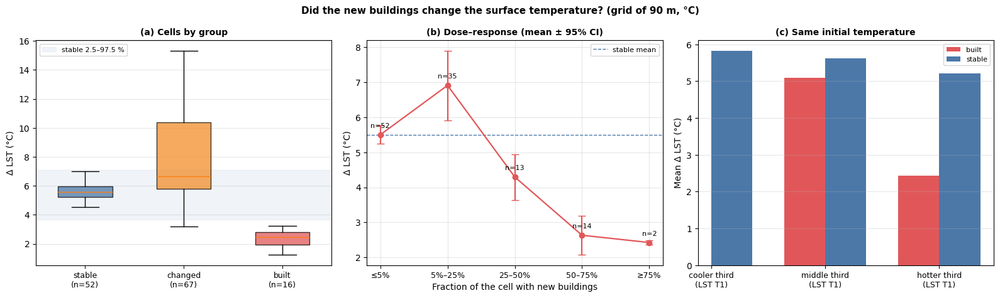

In [22]:
# @title 9.1b — Was the Change Enough to Affect the LST? (grid analysis) {display-mode: "form"}
# @markdown In 9.1, every pixel without new buildings is a control, including lots that were **cleared** and also warmed.
# @markdown Here the area is divided into cells close to the 100 m thermal resolution and the cells are split into three groups:
# @markdown * **built** — at least the threshold below covered by new buildings (U-Net mask);
# @markdown * **changed** — no new buildings, but a large change in the indices below (e.g. clearing, vegetation loss);
# @markdown * **stable** — no new buildings and small changes in the indices.
# @markdown
# @markdown *built − stable* is the effect of the new buildings; *changed − stable* the effect of the other changes.
# @markdown "Enough to affect the LST" is judged by magnitude: is the built group outside the 2.5–97.5 % range of stable cells,
# @markdown and does the response grow with the fraction of the cell that was built (dose–response, controlling for LST and SAVI in T1)?
# @markdown
# @markdown **Prerequisite:** cells 5.1 and 6.5.
# @markdown
# @markdown ---
resposta_91b = 'Δ LST (°C)'  # @param ['Δ LST (°C)', 'Δ UHI (z, relative to the city)']
tamanho_celula = 90  # @param [90, 120, 150] {type:"raw"}
limiar_construido = 0.5  # @param {type:"slider", min:0.2, max:0.9, step:0.1}
indices_mudanca = "SAVI, DBSI"  # @param {type:"string"}
n_boot_91b = 500  # @param {type:"slider", min:100, max:2000, step:100}

from modulos.stats_analysis import (analyze_new_buildings_grid, print_new_buildings_grid_summary,
                                    plot_new_buildings_grid)
from modulos.spectral_analysis import calculate_spectral_indices_dynamic
import matplotlib.pyplot as plt

def _s2_index_91b(name, period):
    key = 't1' if period == 'T1' else 't2'
    cached = results_bitemporal['indices_sentinel2'][key]
    if name.lower() in cached:
        return cached[name.lower()]
    res = calculate_spectral_indices_dynamic(results_bitemporal[key]['sentinel2_image'], [name],
                                             sensor='sentinel2', verbose=False)
    return res.get(name.lower())

try:
    _names = [x.strip().upper() for x in indices_mudanca.split(',') if x.strip()]
    _chg = {}
    for _n in _names:
        _a, _b = _s2_index_91b(_n, 'T1'), _s2_index_91b(_n, 'T2')
        if _a is not None and _b is not None:
            _chg[_n] = (_a, _b)
        else:
            print(f'   ✗ Could not compute {_n}')
    _savi_t1 = _s2_index_91b('SAVI', 'T1')
    res_grid = analyze_new_buildings_grid(
        mask_ee,
        results_bitemporal['lst_30m_t1'], results_bitemporal['lst_30m_t2'],
        roi, config_bitemporal['export_crs'],
        controls_t1={'SAVI': _savi_t1} if _savi_t1 is not None else None,
        change_indices=_chg,
        uhi_t1_image=stats_change['UHI_30m']['images']['t1'],
        uhi_t2_image=stats_change['UHI_30m']['images']['t2'],
        response='duhi' if resposta_91b.startswith('Δ UHI') else 'dlst',
        cell_size=int(tamanho_celula),
        built_threshold=float(limiar_construido),
        n_boot=n_boot_91b,
    )
    print_new_buildings_grid_summary(res_grid)
    _fig = plot_new_buildings_grid(res_grid)
    display(_fig)
    plt.close(_fig)
except NameError as e:
    print(f'⚠️  Variable not found: {e} — run cells 5.1 and 6.5 first.')
except ValueError as e:
    print(f'⚠️  {e}')



ZONAL ANALYSIS BY UHI CLASSES (Deng et al., 2023)
   Bands for sampling: uhi_zone, LST, 
   Requested samples: 2000
   Sampling via stratifiedSample...
   ✓ 191 samples retrieved

────────────────────────────────────────────────────────────────────────────────
Zone                    LST       N
────────────────────────────────────────────────────────────────────────────────
LTZ (Low)            2.2245     109
SLTZ (Sub-Low)       3.4605      23
MTZ (Medium)         5.1759      38
SHTZ (Sub-High)      6.4732       6
HTZ (High)          10.3491      15
────────────────────────────────────────────────────────────────────────────────


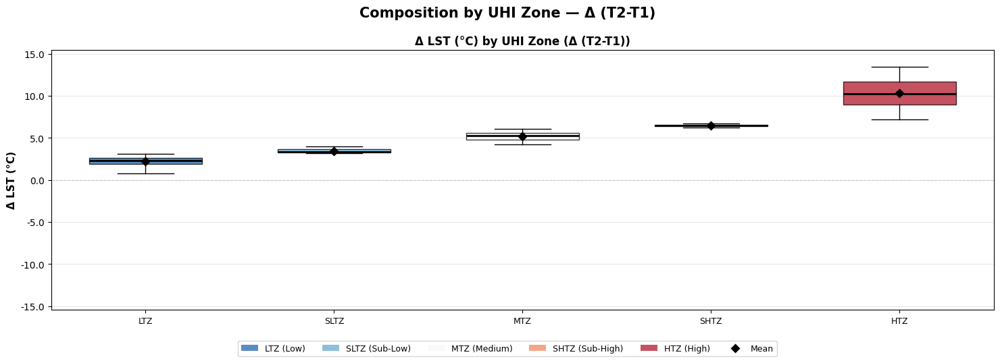

Map(center=[-3.6595608533858632, -40.384409980402324], controls=(WidgetControl(options=['position', 'transpare…

In [23]:
# @title 9.2 — Index Profile in New Buildings Region {display-mode: "form"}
# @markdown Similar to the analysis in cell 8.2,
# @markdown but restricted to pixels detected as **new buildings** by the change mask (U-Net).
# @markdown
# @markdown > If `delta`, analyzes the **variation** between T1 and T2. If `T1` or `T2`, analyzes
# @markdown the absolute value of a single period — always within the new buildings area.

# @markdown ---
# @markdown **This cell generates:**
# @markdown * (1) Boxplots with the temperature and index distribution
# @markdown in each heat zone **inside the change mask**;
# @markdown * (2) Interactive map with the
# @markdown UHI zones and the index restricted to the change mask over the full RGB.
# @markdown
# @markdown ---
# @markdown Configuration
# @markdown
# @markdown **Period to analyze:**
periodo_921         = 'delta'  # @param ['T1', 'T2', 'delta']
indices_921_analise = ''   # @param {type: "string"}
# @markdown
# @markdown ---
# @markdown Note: By adding the indices, period t2 tends to correspond
# @markdown to a constructed composition. Within the constructed stratification,
# @markdown there may not be all categories of UHI.

n_samples_921       = 2000

from modulos.zonal_analysis import (analyze_uhi_zones, plot_uhi_zones_boxplots,
    plot_uhi_spectral_profile, compute_global_band_limits,
    create_uhi_zones_map)
from modulos.spectral_analysis import calculate_spectral_indices_dynamic
import matplotlib.pyplot as plt

# ─── HELPERS (self-contained cell, does not depend on 9.1) ─────────────────────────────────
def _resolve_s2_921(nome, periodo, s2_t1_img, s2_t2_img):
    src = (results_bitemporal['indices_sentinel2']['t1'] if periodo == 'T1'
           else results_bitemporal['indices_sentinel2']['t2'])
    if 'indices_sentinel2_t1' in globals():
        extra = indices_sentinel2_t1 if periodo == 'T1' else indices_sentinel2_t2
        src = {**src, **extra}
    if nome.lower() in src:
        return src[nome.lower()]
    img = s2_t1_img if periodo == 'T1' else s2_t2_img
    result = calculate_spectral_indices_dynamic(img, [nome], sensor='sentinel2', verbose=False)
    return result.get(nome.lower()) or result.get(nome.upper())

try:
    indices_list = [x.strip().upper() for x in indices_921_analise.split(',') if x.strip()]

    # ─── DATA SOURCES ────────────────────────────────────────────────────────────────────
    s2_t1 = results_bitemporal['t1']['sentinel2_image']
    s2_t2 = results_bitemporal['t2']['sentinel2_image']

    uhi_t1 = stats_change['UHI_30m']['images']['t1']
    uhi_t2 = stats_change['UHI_30m']['images']['t2']

    lst_t1 = results_bitemporal['lst_30m_t1']
    lst_t2 = results_bitemporal['lst_30m_t2']

    # ─── CHANGE MASK: selective application ─────────────────────────────────────────────────
    # Analytical data → masked (restricts sampling and UHI/index layers to the new buildings region)
    uhi_t1_m = uhi_t1.updateMask(mask_ee)
    uhi_t2_m = uhi_t2.updateMask(mask_ee)
    lst_t1_m = lst_t1.updateMask(mask_ee)
    lst_t2_m = lst_t2.updateMask(mask_ee)
    # RGB → unmasked (full background in the interactive map)
    sentinel_t1_rgb = results_bitemporal['s2_median_t1']
    sentinel_t2_rgb = results_bitemporal['s2_median_t2']

    if periodo_921 == 'delta':
        uhi_img      = uhi_t2_m.subtract(uhi_t1_m)
        lst_img      = lst_t2_m.subtract(lst_t1_m)
        sentinel_img = sentinel_t2_rgb
    elif periodo_921 == 'T1':
        uhi_img      = uhi_t1_m
        lst_img      = lst_t1_m
        sentinel_img = sentinel_t1_rgb
    else:
        uhi_img      = uhi_t2_m
        lst_img      = lst_t2_m
        sentinel_img = sentinel_t2_rgb

    # ─── BUILD INDEX DICTIONARIES ───────────────────────────────────────────────────────────
    def _build_idx_921(periodo, mask):
        d = {}
        for idx_name in indices_list:
            img = _resolve_s2_921(idx_name, periodo, s2_t1, s2_t2)
            if img is not None:
                d[idx_name] = img.updateMask(mask)
            else:
                print(f'   ✗ Could not compute {idx_name} ({periodo})')
        return d

    # ─── ZONAL ANALYSIS ──────────────────────────────────────────────────────────────────
    if periodo_921 == 'delta':
        indices_dict = {}
        for idx_name in indices_list:
            img_t1 = _resolve_s2_921(idx_name, 'T1', s2_t1, s2_t2)
            img_t2 = _resolve_s2_921(idx_name, 'T2', s2_t1, s2_t2)
            if img_t1 is not None and img_t2 is not None:
                indices_dict[idx_name] = img_t2.subtract(img_t1).updateMask(mask_ee)
            else:
                print(f'   ✗ Could not compute {idx_name}')

        result_zones_921 = analyze_uhi_zones(
            uhi_image=uhi_img, lst_image=lst_img,
            indices_dict=indices_dict,
            roi=roi, scale=30, n_samples=n_samples_921
        )
        band_limits_global = None

    else:
        # Sample both periods to standardize Y-axis scales across sessions
        indices_dict_t1 = _build_idx_921('T1', mask_ee)
        indices_dict_t2 = _build_idx_921('T2', mask_ee)

        result_zones_t1_921 = analyze_uhi_zones(
            uhi_image=uhi_t1_m, lst_image=lst_t1_m,
            indices_dict=indices_dict_t1,
            roi=roi, scale=30, n_samples=n_samples_921
        )
        result_zones_t2_921 = analyze_uhi_zones(
            uhi_image=uhi_t2_m, lst_image=lst_t2_m,
            indices_dict=indices_dict_t2,
            roi=roi, scale=30, n_samples=n_samples_921
        )

        if result_zones_t1_921 is not None and result_zones_t2_921 is not None:
            band_limits_global = compute_global_band_limits(result_zones_t1_921, result_zones_t2_921)
        else:
            band_limits_global = None

        result_zones_921 = result_zones_t1_921 if periodo_921 == 'T1' else result_zones_t2_921
        indices_dict = indices_dict_t1 if periodo_921 == 'T1' else indices_dict_t2

    if result_zones_921 is not None:
        fig_bp = plot_uhi_zones_boxplots(result_zones_921, periodo=periodo_921,
                                         band_limits=band_limits_global)
        display(fig_bp)
        plt.close(fig_bp)

        fig_prof = plot_uhi_spectral_profile(result_zones_921, periodo=periodo_921)
        if fig_prof is not None:
            display(fig_prof)
            plt.close(fig_prof)

        Map_uhi_921 = create_uhi_zones_map(
            uhi_classified=result_zones_921['uhi_classified'].updateMask(mask_ee),
            roi=roi,
            sentinel_image=sentinel_img,
            zoom=zoom_map,
            periodo=periodo_921,
            sentinel_image_t1=sentinel_t1_rgb if periodo_921 == 'delta' else None,
            indices_dict=indices_dict
        )
        display(Map_uhi_921)

except NameError as e:
    print(f'⚠️ Variable not found: {e}')
    print('   Verify that sections 1–8 were run (results_bitemporal, stats_change, mask_ee, roi).')
except Exception as e:
    print(f'✗ Error: {e}')
    import traceback; traceback.print_exc()


In [ ]:
# @title 9.3 — Do the Results Hold for Other Acquisition Dates? {display-mode: "form"}
# @markdown A single pair of Landsat scenes mixes land-cover change with the weather and season of each day
# @markdown (Silva and Torres, 2021). This cell recomputes the thermal results for other date choices,
# @markdown **keeping the change mask and the Sentinel-2 indices fixed**:
# @markdown * **Selected pair** — the images chosen in 3.2 / 3.4;
# @markdown * **Anniversary pair** — two Landsat scenes from the same calendar day (removes the seasonal offset);
# @markdown * **Seasonal median** — median of all clear scenes of the same season in each year (as Campelo et al., 2026, aggregate many scenes per season).
# @markdown
# @markdown A result is robust when *built − stable* keeps its sign and its interval excludes 0 in every scenario.
# @markdown
# @markdown **Prerequisite:** cells 5.1, 6.5 and 9.1b.
# @markdown
# @markdown ---
# @markdown **Anniversary pair** (leave empty to skip):
aniv_landsat_t1 = 'LC08_218063_20190927'  # @param {type:"string"}
aniv_landsat_t2 = 'LC08_218063_20250927'  # @param {type:"string"}
# @markdown **Seasonal median** (leave empty to skip):
season_t1_start = '2019-08-01'  # @param {type:"date"}
season_t1_end = '2019-10-31'  # @param {type:"date"}
season_t2_start = '2025-08-01'  # @param {type:"date"}
season_t2_end = '2025-10-31'  # @param {type:"date"}
season_landsat = 'L8+L9'  # @param ['L8', 'L8+L9']
season_cloud_cover = 10  # @param {type:"slider", min:1, max:30, step:1}
# @markdown ---
resposta_93 = 'Δ LST (°C)'  # @param ['Δ LST (°C)', 'Δ UHI (z, relative to the city)']
n_boot_93 = 500  # @param {type:"slider", min:100, max:2000, step:100}

from modulos.robustness import (thermal_date_sensitivity, print_thermal_sensitivity,
                                plot_thermal_sensitivity)
import matplotlib.pyplot as plt

try:
    _sel = {}
    for _k, _cfg in (('t1', config_t1), ('t2', config_t2)):
        _sel[_k] = ({'landsat_id': _cfg['landsat_id']} if _cfg.get('landsat_id') and _cfg.get('sentinel2_id')
                    else {'start': _cfg['start_date'], 'end': _cfg['end_date'], 'cloud_cover': _cfg['cloud_cover']})
    scenarios_93 = {'Selected pair': _sel}
    if aniv_landsat_t1.strip() and aniv_landsat_t2.strip():
        scenarios_93['Anniversary pair'] = {'t1': {'landsat_id': aniv_landsat_t1.strip()},
                                            't2': {'landsat_id': aniv_landsat_t2.strip()}}
    if season_t1_start and season_t2_start:
        scenarios_93['Seasonal median'] = {
            't1': {'start': season_t1_start, 'end': season_t1_end, 'landsat_type': season_landsat,
                   'cloud_cover': season_cloud_cover},
            't2': {'start': season_t2_start, 'end': season_t2_end, 'landsat_type': season_landsat,
                   'cloud_cover': season_cloud_cover}}

    res_dates = thermal_date_sensitivity(
        scenarios_93, roi, results_bitemporal['t1']['s2_projection'], mask_ee,
        config_bitemporal['export_crs'],
        reference_geometry=results_bitemporal.get('reference_geometry'),
        index_names=[i for i in globals().get('indices_analise', ['SAVI', 'DBSI', 'NBAI'])],
        controls_t1={'SAVI': _savi_t1} if globals().get('_savi_t1') is not None else None,
        change_indices=globals().get('_chg'),
        response_grid='duhi' if resposta_93.startswith('Δ UHI') else 'dlst',
        landsat_type=config_t1.get('landsat_type', 'L8'),
        n_boot=n_boot_93,
    )
    print_thermal_sensitivity(res_dates)
    if res_dates['rows']:
        _fig = plot_thermal_sensitivity(res_dates)
        display(_fig)
        plt.close(_fig)
except NameError as e:
    print(f'⚠️  Variable not found: {e} — run cells 5.1, 6.5 and 9.1b first.')

## Section 10 — Export to Google Drive 💾
Exports selected products to Google Drive.

In [ ]:
# @title 10.1 — Visualize Final Results (T1 and T2) {display-mode: "form"}
# @markdown Generates an interactive map panel with all computed products (LST, UHI, spectral indices) for periods T1 and T2 side by side.
visualize_bitemporal_results(results_bitemporal, roi, zoom=zoom_map, stats_change=stats_change)



🗺️  Creating bitemporal visualization...
   Adding UHI layers...
   Adding UHI Intensity Classification layers...
   Adding legends...
✓ Visualization created


Map(center=[-3.659560852057608, -40.3844099800147], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# @title 10.2 — Export Global Results {display-mode: "form"}
# @markdown Select which products to export to Google Drive:
export_lst_30m           = False   # @param {type: "boolean"}
export_uhi_30m           = False   # @param {type: "boolean"}
export_uhi_intensity_30m = False   # @param {type: "boolean"}
export_landsat           = False  # @param {type: "boolean"}
export_landsat_indices   = False  # @param {type: "boolean"}
export_sentinel2         = False   # @param {type: "boolean"}
export_sentinel1         = False  # @param {type: "boolean"}
export_sentinel2_indices = False   # @param {type: "boolean"}

# @markdown ---
# @markdown **Deltas (T2 - T1):**
export_delta_lst_30m           = False  # @param {type: "boolean"}
export_delta_landsat_indices   = False  # @param {type: "boolean"}
export_delta_sentinel2_indices = False  # @param {type: "boolean"}
export_delta_uhi_30m           = False  # @param {type: "boolean"}
export_delta_uhi_intensity_30m = False  # @param {type: "boolean"}

# # @markdown **CDI = Δ LST × Δ Index [(Silva & Torres, 2021)](https://doi.org/10.1016/j.buildenv.2021.107634):**
export_cdi_landsat   = False
export_cdi_sentinel2 = False

# @markdown ---
# @markdown Landsat indices to export (comma-separated, or **all** for all):
landsat_indices_export = "SAVI, DBSI, NBAI"  # @param {type: "string"}

# @markdown Sentinel-2 indices to export (comma-separated):
sentinel2_indices_export = "SAVI, DBSI, NBAI"  # @param {type: "string"}

_landsat_list  = "all" if landsat_indices_export.strip().lower() == "all" else [x.strip() for x in landsat_indices_export.split(",")]
_s2_list       = [x.strip() for x in sentinel2_indices_export.split(",")]

tasks = export_bitemporal_results(
    results_bitemporal,
    config_bitemporal,
    config_t1["geometry"],
    stats_change=stats_change,
    export_lst_30m=export_lst_30m,
    export_uhi_30m=export_uhi_30m,
    export_uhi_intensity_30m=export_uhi_intensity_30m,
    export_landsat=export_landsat,
    export_sentinel2=export_sentinel2,
    export_sentinel1=export_sentinel1,
    export_landsat_indices=export_landsat_indices,
    export_sentinel2_indices=export_sentinel2_indices,
    landsat_indices_list=_landsat_list,
    sentinel2_indices_list=_s2_list,
    export_delta_lst_30m=export_delta_lst_30m,
    export_delta_landsat_indices=export_delta_landsat_indices,
    export_delta_sentinel2_indices=export_delta_sentinel2_indices,
    export_delta_uhi_30m=export_delta_uhi_30m,
    export_delta_uhi_intensity_30m=export_delta_uhi_intensity_30m,
    export_cdi_landsat=export_cdi_landsat,
    export_cdi_sentinel2=export_cdi_sentinel2,
)

print(f"✅ Export complete!")
print(f"Monitor progress at: https://code.earthengine.google.com/tasks")



EXPORTING SELECTED PRODUCTS TO GOOGLE DRIVE
Determined CRS: EPSG:32724

📋 EXPORT SUMMARY:
  • LST 30m (Landsat): NO
  • LST 10m (Downscaled): NO
  • UHI 30m (Normalized): NO
  • UHI 10m (Normalized): NO
  • UHI Intensity Classification 30m (Deng et al. 2023): NO
  • UHI Intensity Classification 10m (Deng et al. 2023): NO
  • Landsat Indices (30m): NO
  • Landsat SR Imagery (30m): NO
  • Delta LST 30m T2-T1: NO
  • Delta LST 10m T2-T1: NO
  • Delta Landsat Indices T2-T1 (30m): NO
  • Delta Sentinel-2 Indices T2-T1 (10m): NO
  • Delta UHI 30m T2-T1: YES
  • Delta UHI Intensity 30m T2-T1: NO
  • Delta UHI 10m T2-T1: NO
  • Delta UHI Intensity 10m T2-T1: NO
  • CDI Landsat (dLST_30m x dIndex, 30m): NO
  • CDI Sentinel-2 (dLST_30m x dIndex, 10m): NO

EXPORTING DELTA UHI 30m (T2 - T1)
  Note: Delta of z-score UHI values (positive = UHI increased)
  ✓ Delta UHI 30m started

✅ 1 EXPORTS STARTED SUCCESSFULLY!

📂 Location: Google Drive/Data/
🔗 Monitor at: https://code.earthengine.google.com/tas

In [ ]:
# @title 10.3 — Export Change Detection Filtered Results {display-mode: "form"}
# @markdown Exports rasters **restricted to the binary change detection mask** (new buildings detected by U-Net).
# @markdown Requires `mask_ee`, `results_bitemporal`, `stats_change`, and `config_bitemporal`
# @markdown to be available — run sections 5–9 before this cell.
# @markdown
# @markdown ---
# @markdown **Binary mask:**
export_mask_binary           = False  # @param {type: "boolean"}
# @markdown **LST within change area (T1 / T2):**
export_mask_lst_t1           = False  # @param {type: "boolean"}
export_mask_lst_t2           = False  # @param {type: "boolean"}
# @markdown **UHI 30m within change area (T1 / T2):**
export_mask_uhi_t1           = False  # @param {type: "boolean"}
export_mask_uhi_t2           = False  # @param {type: "boolean"}
# @markdown **UHI Intensity 30m within change area (T1 / T2):**
export_mask_uhi_intensity_t1 = False  # @param {type: "boolean"}
export_mask_uhi_intensity_t2 = False  # @param {type: "boolean"}
# @markdown **Deltas within change area (T2 − T1):**
export_mask_delta_lst        = False  # @param {type: "boolean"}
export_mask_delta_uhi              = False  # @param {type: "boolean"}
export_mask_delta_uhi_intensity    = False  # @param {type: "boolean"}
# @markdown ---
# @markdown **Sentinel-2 indices within change area (10 m):**
export_mask_s2_indices_t1    = False  # @param {type: "boolean"}
export_mask_s2_indices_t2    = False  # @param {type: "boolean"}
export_mask_s2_indices_delta = False  # @param {type: "boolean"}
export_mask_cdi_sentinel2    = False
# @markdown **Landsat indices within change area (30 m):**
export_mask_landsat_indices_t1    = False  # @param {type: "boolean"}
export_mask_landsat_indices_t2    = False  # @param {type: "boolean"}
export_mask_landsat_indices_delta = False  # @param {type: "boolean"}
export_mask_cdi_landsat           = False
# @markdown ---
# @markdown Sentinel-2 index list (comma-separated):
mask_s2_indices      = "SAVI"  # @param {type: "string"}
# @markdown Landsat index list (comma-separated):
mask_landsat_indices = "SAVI, DBSI, NBAI"  # @param {type: "string"}

import ee
from modulos.spectral_analysis import calculate_spectral_indices_dynamic

try:
    # ── Validate dependencies ──────────────────────────────────────────────
    for _var in ('mask_ee', 'results_bitemporal', 'stats_change', 'config_bitemporal', 'roi'):
        if _var not in globals():
            raise NameError(_var)

    _site   = config_bitemporal['site_name']
    _folder = config_bitemporal['export_folder']
    _crs    = config_bitemporal['export_crs']

    _s2_list      = [x.strip().upper() for x in mask_s2_indices.split(',') if x.strip()]
    _landsat_list = [x.strip().upper() for x in mask_landsat_indices.split(',') if x.strip()]

    _tasks = []

    def _start_103(image, name, scale=30):
        try:
            t = ee.batch.Export.image.toDrive(
                image=image,
                description=name,
                folder=_folder,
                fileNamePrefix=name.lower(),
                region=roi,
                crs=_crs,
                scale=scale,
                maxPixels=1e13,
                fileFormat='GeoTIFF',
                formatOptions={'cloudOptimized': True}
            )
            t.start()
            _tasks.append(t)
            print(f'  ✓ {name}')
        except Exception as e:
            print(f'  ✗ {name}: {e}')

    def _resolve_index(name, sensor, period):
        key = 't1' if period == 'T1' else 't2'
        store_key = 'indices_sentinel2' if sensor == 's2' else 'indices_landsat'
        cached = results_bitemporal.get(store_key, {}).get(key, {})
        img = cached.get(name.lower()) or cached.get(name.upper())
        if img is not None:
            return img
        # Fallback: compute dynamically
        sensor_label = 'sentinel2' if sensor == 's2' else 'landsat'
        src_key = 'sentinel2_image' if sensor == 's2' else 'landsat_image'
        src_img = results_bitemporal[key].get(src_key)
        if src_img is None:
            print(f'    ⚠️  Source image not found for {sensor_label} {period}')
            return None
        result = calculate_spectral_indices_dynamic(src_img, [name], sensor=sensor_label, verbose=False)
        return result.get(name.lower()) or result.get(name.upper())

    def _to_10m(img):
        # Reproject image to mask scale (10m) using bilinear resampling.
        # Images already at 10m (S2 indices) pass through unchanged.
        # 30m Landsat products are bilinearly interpolated to fill the 10m mask grid
        # without gaps caused by center-point sampling misalignment.
        try:
            native_scale = img.projection().nominalScale().getInfo()
        except Exception:
            native_scale = 30
        if native_scale <= 10:
            return img
        return img.resample('bilinear').reproject(
            crs=mask_ee.projection(), scale=10)

    # ── Source images ──────────────────────────────────────────────────────
    _uhi_t1 = stats_change['UHI_30m']['images']['t1']
    _uhi_t2 = stats_change['UHI_30m']['images']['t2']
    _lst_t1 = results_bitemporal['lst_30m_t1']
    _lst_t2 = results_bitemporal['lst_30m_t2']
    _dlst   = _lst_t2.subtract(_lst_t1)

    # UHI intensity classified images (pre-computed, same source as cell 10.2)
    _intensity_cls = stats_change.get('UHI_30m', {}).get('intensity_classification', {})
    _uhi_int_t1    = _intensity_cls.get('t1')
    _uhi_int_t2    = _intensity_cls.get('t2')

    print('=' * 70)
    print('EXPORTING CHANGE DETECTION FILTERED PRODUCTS')
    print('=' * 70)
    print(f'Site   : {_site}')
    print(f'Folder : {_folder}')
    print(f'CRS    : {_crs}')

    # ── Binary mask ────────────────────────────────────────────────────────
    if export_mask_binary:
        print('\n— Binary mask')
        _start_103(mask_ee.rename('change_mask'), f'ChangeMask_{_site}', scale=10)

    # ── LST ───────────────────────────────────────────────────────────────
    if export_mask_lst_t1 or export_mask_lst_t2:
        print('\n— LST')
    if export_mask_lst_t1:
        _start_103(_to_10m(_lst_t1).updateMask(mask_ee), f'LST_mask_{_site}_T1', scale=10)
    if export_mask_lst_t2:
        _start_103(_to_10m(_lst_t2).updateMask(mask_ee), f'LST_mask_{_site}_T2', scale=10)

    # ── UHI ───────────────────────────────────────────────────────────────
    if export_mask_uhi_t1 or export_mask_uhi_t2:
        print('\n— UHI 30m')
    if export_mask_uhi_t1:
        _start_103(_to_10m(_uhi_t1).updateMask(mask_ee), f'UHI_30m_mask_{_site}_T1', scale=10)
    if export_mask_uhi_t2:
        _start_103(_to_10m(_uhi_t2).updateMask(mask_ee), f'UHI_30m_mask_{_site}_T2', scale=10)

    # ── UHI Intensity ─────────────────────────────────────────────────────
    if export_mask_uhi_intensity_t1 or export_mask_uhi_intensity_t2:
        print('\n— UHI Intensity 30m')
        if _uhi_int_t1 is None or _uhi_int_t2 is None:
            print('  ⚠️  intensity_classification not found in stats_change — run cell 5.1 first')
    if export_mask_uhi_intensity_t1:
        if _uhi_int_t1 is not None:
            _start_103(_to_10m(_uhi_int_t1).updateMask(mask_ee),
                       f'UHI_Intensity_30m_mask_{_site}_T1', scale=10)
    if export_mask_uhi_intensity_t2:
        if _uhi_int_t2 is not None:
            _start_103(_to_10m(_uhi_int_t2).updateMask(mask_ee),
                       f'UHI_Intensity_30m_mask_{_site}_T2', scale=10)

    # ── Deltas ────────────────────────────────────────────────────────────
    if export_mask_delta_lst or export_mask_delta_uhi:
        print('\n— Deltas (T2 − T1)')
    if export_mask_delta_lst:
        _start_103(_to_10m(_dlst).updateMask(mask_ee), f'dLST_mask_{_site}', scale=10)
    if export_mask_delta_uhi:
        _start_103(_to_10m(_uhi_t2.subtract(_uhi_t1)).updateMask(mask_ee),
                   f'dUHI_30m_mask_{_site}', scale=10)
    if export_mask_delta_uhi_intensity:
        if _uhi_int_t1 is not None and _uhi_int_t2 is not None:
            _delta_cls = _to_10m(_uhi_int_t2.subtract(_uhi_int_t1)).updateMask(mask_ee)
            _start_103(_delta_cls, f'dUHI_Intensity_30m_mask_{_site}', scale=10)
        else:
            print('  ⚠️  intensity_classification not found in stats_change — run cell 5.1 first')

    # ── Sentinel-2 indices ────────────────────────────────────────────────
    _need_s2 = (export_mask_s2_indices_t1 or export_mask_s2_indices_t2
                or export_mask_s2_indices_delta or export_mask_cdi_sentinel2)
    if _need_s2 and _s2_list:
        print(f'\n— Sentinel-2 indices (10 m): {", ".join(_s2_list)}')
        for _idx in _s2_list:
            _need_t1 = export_mask_s2_indices_t1 or export_mask_s2_indices_delta or export_mask_cdi_sentinel2
            _need_t2 = export_mask_s2_indices_t2 or export_mask_s2_indices_delta or export_mask_cdi_sentinel2
            _img_t1 = _resolve_index(_idx, 's2', 'T1') if _need_t1 else None
            _img_t2 = _resolve_index(_idx, 's2', 'T2') if _need_t2 else None

            if export_mask_s2_indices_t1 and _img_t1 is not None:
                _start_103(_img_t1.updateMask(mask_ee),
                            f'S2_{_idx}_mask_{_site}_T1', scale=10)
            if export_mask_s2_indices_t2 and _img_t2 is not None:
                _start_103(_img_t2.updateMask(mask_ee),
                            f'S2_{_idx}_mask_{_site}_T2', scale=10)
            if export_mask_s2_indices_delta and _img_t1 is not None and _img_t2 is not None:
                _start_103(_img_t2.subtract(_img_t1).updateMask(mask_ee),
                            f'S2_d{_idx}_mask_{_site}', scale=10)
            if export_mask_cdi_sentinel2 and _img_t1 is not None and _img_t2 is not None:
                _cdi = _dlst.updateMask(mask_ee).multiply(
                    _img_t2.subtract(_img_t1).updateMask(mask_ee))
                _start_103(_cdi, f'CDI_S2_{_idx}_mask_{_site}', scale=10)

    # ── Landsat indices ───────────────────────────────────────────────────
    _need_ls = (export_mask_landsat_indices_t1 or export_mask_landsat_indices_t2
                or export_mask_landsat_indices_delta or export_mask_cdi_landsat)
    if _need_ls and _landsat_list:
        print(f'\n— Landsat indices (30 m): {", ".join(_landsat_list)}')
        for _idx in _landsat_list:
            _need_t1 = export_mask_landsat_indices_t1 or export_mask_landsat_indices_delta or export_mask_cdi_landsat
            _need_t2 = export_mask_landsat_indices_t2 or export_mask_landsat_indices_delta or export_mask_cdi_landsat
            _img_t1 = _resolve_index(_idx, 'landsat', 'T1') if _need_t1 else None
            _img_t2 = _resolve_index(_idx, 'landsat', 'T2') if _need_t2 else None

            if export_mask_landsat_indices_t1 and _img_t1 is not None:
                _start_103(_to_10m(_img_t1).updateMask(mask_ee),
                            f'L8_{_idx}_mask_{_site}_T1', scale=10)
            if export_mask_landsat_indices_t2 and _img_t2 is not None:
                _start_103(_to_10m(_img_t2).updateMask(mask_ee),
                            f'L8_{_idx}_mask_{_site}_T2', scale=10)
            if export_mask_landsat_indices_delta and _img_t1 is not None and _img_t2 is not None:
                _start_103(_to_10m(_img_t2.subtract(_img_t1)).updateMask(mask_ee),
                            f'L8_d{_idx}_mask_{_site}', scale=10)
            if export_mask_cdi_landsat and _img_t1 is not None and _img_t2 is not None:
                _dlst_30 = results_bitemporal['lst_30m_t2'].subtract(
                    results_bitemporal['lst_30m_t1'])
                _cdi = _to_10m(_dlst_30).multiply(
                    _to_10m(_img_t2.subtract(_img_t1))).updateMask(mask_ee)
                _start_103(_cdi, f'CDI_L8_{_idx}_mask_{_site}', scale=10)

    print()
    if _tasks:
        print(f'✅ {len(_tasks)} task(s) started.')
        print('Monitor at: https://code.earthengine.google.com/tasks')
    else:
        print('⚠️  No product selected. Enable at least one option above.')

except NameError as e:
    print(f'⚠️  Variable not found: {e}')
    print('   Run sections 5–9 (results_bitemporal, stats_change, mask_ee) before this cell.')
except Exception as e:
    print(f'✗ Error: {e}')
    import traceback; traceback.print_exc()


EXPORTING CHANGE DETECTION FILTERED PRODUCTS
Site   : A_Zone
Folder : Data
CRS    : EPSG:32724

— UHI Intensity 30m
  ✓ UHI_Intensity_30m_mask_A_Zone_T1
  ✓ UHI_Intensity_30m_mask_A_Zone_T2

✅ 2 task(s) started.
Monitor at: https://code.earthengine.google.com/tasks


---
# ✅ Pipeline Complete!

All results processed. Check:
- **Google Drive** — Products exported to the folder configured in Section 4
- **Local file** — `pred_{roi_name}.tif` with the change map (Section 6)
- **Interactive maps** — Visualizations generated in the sections above